# Predicting Division I Men's Basketball Transfer Portal Starters

**Team members:** Aurea McIntosh, Zoe Edelblum, Evie McMahan

**Repository:** https://github.com/eviemcmahan/ds_3001_project_team_6.git

# **Setup**

Use relative paths and keep the notebook runnable from beginning to end.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."

# **Load data**

In [2]:
# Load data from DATA_DIR.
import pandas as pd

espn_rankings = pd.read_csv(DATA_DIR / "espn_preseason_rankings.csv")
player_stats_2020 = pd.read_csv(DATA_DIR / "player_stats_2020.csv")
player_stats_2021 = pd.read_csv(DATA_DIR / "player_stats_2021.csv")
player_stats_2022 = pd.read_csv(DATA_DIR / "player_stats_2022.csv")
player_stats_2023 = pd.read_csv(DATA_DIR / "player_stats_2023.csv")
player_stats_2024 = pd.read_csv(DATA_DIR / "player_stats_2024.csv")
player_stats_2025 = pd.read_csv(DATA_DIR / "player_stats_2025.csv")
player_stats_2026 = pd.read_csv(DATA_DIR / "player_stats_2026.csv")

# **Prepare data**

In [3]:
# Clean data and create features.
espn_rankings.info()
print("Missing values:\n", espn_rankings.isna().sum())
print("Duplicate rows:", espn_rankings.duplicated().sum())

datasets = {
    "2020": player_stats_2020,
    "2021": player_stats_2021,
    "2022": player_stats_2022,
    "2023": player_stats_2023,
    "2024": player_stats_2024,
    "2025": player_stats_2025,
    "2026": player_stats_2026,
}

for year, df in datasets.items():
    print(f"\n{'=' * 40}\nPlayer Stats {year}")
    df.info()
    print("Missing values:\n", df.isna().sum())
    print("Duplicate rows:", df.duplicated().sum())

    missing = df.isna().sum()
    missing_pct = (missing / len(df) * 100).round(2)

    missing_summary = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage": missing_pct
    })

    missing_summary = missing_summary[
        missing_summary["Missing Count"] > 0
    ].sort_values("Missing Percentage", ascending=False)

    print(f"\nMissing data for {year}:")
    display(missing_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   season               600 non-null    object 
 1   year                 600 non-null    int64  
 2   espn_preseason_rank  600 non-null    int64  
 3   player               600 non-null    object 
 4   player_key           600 non-null    object 
 5   espn_player_id       597 non-null    float64
 6   height_in            600 non-null    int64  
 7   position             599 non-null    object 
 8   class_prev_season    599 non-null    object 
 9   prev_school          600 non-null    object 
 10  new_school           600 non-null    object 
dtypes: float64(1), int64(3), object(7)
memory usage: 51.7+ KB
Missing values:
 season                 0
year                   0
espn_preseason_rank    0
player                 0
player_key             0
espn_player_id         3
height_in      

,Missing Count,Missing Percentage
conference,4018,45.48
assistsTurnoverRatio,1659,18.78
offensiveReboundPct,1181,13.37
netRating,979,11.08
winShares/totalPer40,979,11.08
winShares/total,979,11.08
winShares/offensive,954,10.80
PORPAG,596,6.75
offensiveRating,595,6.73
freeThrowRate,590,6.68



Player Stats 2021
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6859 entries, 0 to 6858
Data columns (total 47 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   season                          6859 non-null   int64  
 1   seasonLabel                     6859 non-null   int64  
 2   teamId                          6859 non-null   int64  
 3   team                            6859 non-null   object 
 4   conference                      5024 non-null   object 
 5   athleteId                       6859 non-null   int64  
 6   athleteSourceId                 6859 non-null   int64  
 7   name                            6859 non-null   object 
 8   position                        6852 non-null   object 
 9   games                           6859 non-null   int64  
 10  starts                          6859 non-null   int64  
 11  minutes                         6859 non-null   int64  
 12  points         

,Missing Count,Missing Percentage
conference,1835,26.75
assistsTurnoverRatio,1011,14.74
offensiveReboundPct,637,9.29
netRating,531,7.74
winShares/offensive,531,7.74
winShares/total,531,7.74
winShares/totalPer40,531,7.74
PORPAG,395,5.76
offensiveRating,393,5.73
freeThrowRate,391,5.70



Player Stats 2022
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9400 entries, 0 to 9399
Data columns (total 47 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   season                          9400 non-null   int64  
 1   seasonLabel                     9400 non-null   int64  
 2   teamId                          9400 non-null   int64  
 3   team                            9400 non-null   object 
 4   conference                      5096 non-null   object 
 5   athleteId                       9400 non-null   int64  
 6   athleteSourceId                 9400 non-null   int64  
 7   name                            9400 non-null   object 
 8   position                        9395 non-null   object 
 9   games                           9400 non-null   int64  
 10  starts                          9400 non-null   int64  
 11  minutes                         9400 non-null   int64  
 12  points         

,Missing Count,Missing Percentage
conference,4304,45.79
assistsTurnoverRatio,1801,19.16
offensiveReboundPct,1262,13.43
netRating,774,8.23
winShares/totalPer40,774,8.23
winShares/total,774,8.23
winShares/offensive,772,8.21
PORPAG,669,7.12
offensiveRating,667,7.10
freeThrowRate,622,6.62


... (4 outputs left out)


Player Stats 2025
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9808 entries, 0 to 9807
Data columns (total 47 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   season                          9808 non-null   int64  
 1   seasonLabel                     9808 non-null   int64  
 2   teamId                          9808 non-null   int64  
 3   team                            9808 non-null   object 
 4   conference                      5144 non-null   object 
 5   athleteId                       9808 non-null   int64  
 6   athleteSourceId                 9808 non-null   int64  
 7   name                            9808 non-null   object 
 8   position                        9786 non-null   object 
 9   games                           9808 non-null   int64  
 10  starts                          9808 non-null   int64  
 11  minutes                         9808 non-null   int64  
 12  points         

,Missing Count,Missing Percentage
conference,4664,47.55
assistsTurnoverRatio,2023,20.63
offensiveReboundPct,1338,13.64
netRating,919,9.37
winShares/offensive,919,9.37
winShares/total,919,9.37
winShares/totalPer40,919,9.37
offensiveRating,678,6.91
PORPAG,678,6.91
freeThrowRate,652,6.65



Player Stats 2026
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10030 entries, 0 to 10029
Data columns (total 47 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   season                          10030 non-null  int64  
 1   seasonLabel                     10030 non-null  int64  
 2   teamId                          10030 non-null  int64  
 3   team                            10030 non-null  object 
 4   conference                      5035 non-null   object 
 5   athleteId                       10030 non-null  int64  
 6   athleteSourceId                 10030 non-null  int64  
 7   name                            10030 non-null  object 
 8   position                        10029 non-null  object 
 9   games                           10030 non-null  int64  
 10  starts                          10030 non-null  int64  
 11  minutes                         10030 non-null  int64  
 12  points       

,Missing Count,Missing Percentage
conference,4995,49.80
assistsTurnoverRatio,2068,20.62
offensiveReboundPct,1403,13.99
netRating,719,7.17
winShares/totalPer40,719,7.17
winShares/total,719,7.17
winShares/offensive,718,7.16
PORPAG,648,6.46
offensiveRating,647,6.45
freeThrowRate,645,6.43


### Confirm how seasons and IDs line up across datasets ###

**Clean season**

In [4]:
import numpy as np
import matplotlib.pyplot as plt

all_stats = pd.concat(datasets.values(), ignore_index=True) # Combine all datasets to explore values
print(all_stats.groupby("season")[["season", "seasonLabel"]].first()) # Group by season

        season  seasonLabel
season                     
2020      2020     20192020
2021      2021     20202021
2022      2022     20212022
2023      2023     20222023
2024      2024     20232024
2025      2025     20242025
2026      2026     20252026


We will define the season as the year when that season ends. For example, the 2020 season was played over 2019 and 2020. I can now delete the `seasonLabel` column in all the datasets.

In [5]:
for year, df in datasets.items():
    datasets[year] = df.drop(columns=["seasonLabel"]) # Drop seasonLabel for each dataset

print(f"Season Missing values: {all_stats["season"].isna().sum()}") # Determing missing values
datasets['2020'].head() # Check head

Season Missing values: 0


,season,teamId,team,conference,athleteId,athleteSourceId,name,position,games,starts,...,freeThrows/made,freeThrows/attempted,freeThrows/pct,rebounds/offensive,rebounds/defensive,rebounds/total,winShares/offensive,winShares/defensive,winShares/total,winShares/totalPer40
0,2020,1,Abilene Christian,Southland,16870,4433077,Airion Simmons,F,31,0,...,23,39,59.0,40,87,127,0.5,0.9,1.4,0.129
1,2020,1,Abilene Christian,Southland,21203,4397957,Damien Daniels,G,31,15,...,32,43,74.4,16,58,74,0.5,0.8,1.3,0.083
2,2020,1,Abilene Christian,Southland,21204,4278255,Tobias Cameron,G,25,0,...,10,11,90.9,11,17,28,0.3,0.2,0.5,0.143
3,2020,1,Abilene Christian,Southland,21205,4397958,Joe Pleasant,F,29,29,...,68,97,70.1,49,73,122,1.3,0.7,2.0,0.112
4,2020,1,Abilene Christian,Southland,27157,4593748,Mahki Morris,G,17,1,...,14,17,82.4,14,13,27,0.0,0.4,0.4,0.084


The `season` column is good to go.

**Clean athleteID**

In [6]:
print(all_stats[["athleteId", "athleteSourceId"]].nunique()) # How many unique values are in athleteId vs athleteSourceId

print(f"\nathleteSourceIds for each athleteId:\n{all_stats.groupby('athleteId')['athleteSourceId'].nunique().value_counts()}") # Check how many sourceIds there are for each athleteID
print(all_stats[["athleteId", "athleteSourceId"]].head())


athleteId          36464
athleteSourceId    36464
dtype: int64

athleteSourceIds for each athleteId:
athleteSourceId
1    36464
Name: count, dtype: int64
   athleteId  athleteSourceId
0      16870          4433077
1      21203          4397957
2      21204          4278255
3      21205          4397958
4      27157          4593748


`athleteId` and `athleteSourceId` have different values but map one-to-one, so they carry the same information and each have the same number of unique values. Therefore, I will drop one column and just keep `athleteId`.

In [7]:
for year, df in datasets.items():
    datasets[year] = df.drop(columns=["athleteSourceId"]) # Drop athleteSourceId for each dataset

In [8]:
print(f"athleteId missing values: {all_stats['athleteId'].isna().sum()}")
datasets['2020'].head() # Check head

athleteId missing values: 0


,season,teamId,team,conference,athleteId,name,position,games,starts,minutes,...,freeThrows/made,freeThrows/attempted,freeThrows/pct,rebounds/offensive,rebounds/defensive,rebounds/total,winShares/offensive,winShares/defensive,winShares/total,winShares/totalPer40
0,2020,1,Abilene Christian,Southland,16870,Airion Simmons,F,31,0,434,...,23,39,59.0,40,87,127,0.5,0.9,1.4,0.129
1,2020,1,Abilene Christian,Southland,21203,Damien Daniels,G,31,15,630,...,32,43,74.4,16,58,74,0.5,0.8,1.3,0.083
2,2020,1,Abilene Christian,Southland,21204,Tobias Cameron,G,25,0,140,...,10,11,90.9,11,17,28,0.3,0.2,0.5,0.143
3,2020,1,Abilene Christian,Southland,21205,Joe Pleasant,F,29,29,713,...,68,97,70.1,49,73,122,1.3,0.7,2.0,0.112
4,2020,1,Abilene Christian,Southland,27157,Mahki Morris,G,17,1,191,...,14,17,82.4,14,13,27,0.0,0.4,0.4,0.084


In [9]:
rows_per_athlete = all_stats.groupby(["season", "athleteId"]).size() # Group by season and athleteId to see how many ahtletes are featured multiple times in one season
print(f"Rows per athlete within a season:\n{rows_per_athlete.value_counts()}")

print(f"\nNumber of duplicate athletes by season:\n{(rows_per_athlete > 1).groupby("season").sum()}")


Rows per athlete within a season:
1    64405
2       70
Name: count, dtype: int64

Number of duplicate athletes by season:
season
2020    38
2021     5
2022     5
2023     0
2024     0
2025    20
2026     2
dtype: int64


I looked at how many athletes are featured multiple times in just one season, and saw that there are 70 players who appear twice. This means that only 70 out of 64,475 athlete-seasons (0.1%) have a repeat. I am going to see what those 70 cases are. No players appear three times.

In [10]:
duplicates = all_stats[all_stats.duplicated(subset=["season", "athleteId"], keep=False)] # Find all the duplicated players
print(duplicates.sort_values(["athleteId", "season"])[["athleteId", "name", "season", "team", "games", "points"]].to_string(index=False)) # Inspect the duplicated players

 athleteId                 name  season                     team  games  points
      4605        Brendan Terry    2025 Southeast Missouri State     33     370
      4605        Brendan Terry    2025            UNC Asheville      1       7
      4606              TJ Biel    2025 Southeast Missouri State     31     116
      4606              TJ Biel    2025            UNC Asheville      1       0
      4607           Rob Martin    2025 Southeast Missouri State     33     488
      4607           Rob Martin    2025            UNC Asheville      1      13
      4608       Elliot Lowndes    2025 Southeast Missouri State     33      75
      4608       Elliot Lowndes    2025            UNC Asheville      1       5
      4611          David Idada    2025 Southeast Missouri State     33      68
      4611          David Idada    2025            UNC Asheville      1       0
      4612        Troy Cole Jr.    2025 Southeast Missouri State     33     192
      4612        Troy Cole Jr.    2025 

The athletes that are duplicated within a season are shown on different teams in the same season. I did some research, using Brendan Terry as an example, and found that the Southeast Missouri State players who played in their game against UNC Asheville each have a separate row for that game, where they are mislabeled as UNC Asheville players. The points in those rows match the points the players scored in that game's box score.

The only exception is A.J. Lawson. He is the only athlete where one of his two rows isn't a single game. After researching, I found out this is two different A.J. Lawsons with the same `athleteId` (31449). One played for South Carolina, and the other played for McNeese. I will separate these players and give one of them a different `athleteID`.

After this, for each duplicated athlete, I will keep the row with the most games, since that is the team they actually played for.

In [11]:
# athleteId 31449 is shared by two different players named A.J. Lawson (McNeese and South Carolina)
# Give the South Carolina player his own ID so the two are no longer mixed up.
new_id = max(df["athleteId"].max() for df in datasets.values()) + 1 # Determine the max athleteId and add one

for year, df in datasets.items(): # Give the SC player a new athleteId
    is_sc_lawson = (df["athleteId"] == 31449) & (df["team"] == "South Carolina")
    df.loc[is_sc_lawson, "athleteId"] = new_id

In [12]:
for year, df in datasets.items():
    # For athletes with two team rows in one season, keep the row with the most games (or minutes if games are tied)
    df = df.sort_values(["games", "minutes"], ascending=False)
    df = df.drop_duplicates(subset=["season", "athleteId"], keep="first")
    datasets[year] = df.sort_values("athleteId").reset_index(drop=True)

all_stats = pd.concat(datasets.values(), ignore_index=True) # Rebuild combined table from cleaned datasets

print(f"Duplicate athlete-seasons left: {all_stats.duplicated(subset=['season', 'athleteId']).sum()}") # Check how many duplicates are left
print(f"Rows: {len(all_stats)}\n")
print("A.J. Lawson after the split:")
print(all_stats[all_stats["name"] == "A.J. Lawson"][["athleteId", "season", "team", "games"]]
      .sort_values(["athleteId", "season"]).to_string(index=False))
datasets['2020'].head() # Check head


Duplicate athlete-seasons left: 0
Rows: 64477

A.J. Lawson after the split:
 athleteId  season           team  games
     31449    2020        McNeese     32
     31449    2021        McNeese     23
    223021    2020 South Carolina     31
    223021    2021 South Carolina     21


,season,teamId,team,conference,athleteId,name,position,games,starts,minutes,...,freeThrows/made,freeThrows/attempted,freeThrows/pct,rebounds/offensive,rebounds/defensive,rebounds/total,winShares/offensive,winShares/defensive,winShares/total,winShares/totalPer40
0,2020,58,Columbia,Ivy,41,Cameron Shockley-Okeke,F,13,0,143,...,3,4,75.0,5,19,24,-0.4,0.3,-0.1,-0.028
1,2020,235,Providence,Big East,67,Greg Gantt Jr.,F,27,5,338,...,13,19,68.4,26,36,62,0.0,0.7,0.7,0.083
2,2020,299,The Citadel,SoCon,70,Fletcher Abee,G,30,30,969,...,45,53,84.9,10,47,57,1.8,0.4,2.2,0.091
3,2020,145,Long Beach State,Big West,96,Romelle Mansel,F,32,23,631,...,32,65,49.2,29,84,113,-0.7,0.5,-0.2,-0.013
4,2020,148,Louisiana,Sun Belt,122,Mylik Wilson,G,29,24,991,...,48,68,70.6,34,132,166,0.8,1.5,2.3,0.093


The duplicate athletes were handled correctly.

In [13]:
print(f"athleteIds with more than one name: {(all_stats.groupby('athleteId')['name'].nunique() > 1).sum()}") # Check names and athleteId

year_shifted_forward = all_stats.copy() # Copy the table
year_shifted_forward["season"] = year_shifted_forward["season"] + 1 # Add one to each season to check how athleteId's move between the prior season

both_years = all_stats.merge(year_shifted_forward, on=["athleteId", "season"], suffixes=("_this_year", "_last_year")) # Inner join each player's rows with his row from the year before

changed_team = both_years["teamId_this_year"] != both_years["teamId_last_year"] # Check to see if teamId is different from year to year

print(f"Players found in two consecutive seasons: {len(both_years)}")
print(f"Players found in two consecutive seasons who changed teams: {changed_team.sum()}")

athleteIds with more than one name: 0
Players found in two consecutive seasons: 25172
Players found in two consecutive seasons who changed teams: 6194


No `athleteId`s have more than one name, and the same `athleteId` shows up across consecutive seasons, even when a player changes teams, which is great news. There are 6,194 cases of a player appearing on a different team than the season before. This does include non-D1 schools, so this number will shrink once we filter to D1. The `athleteID` column is good to go.

### Build transfers DataFrame

In [14]:
transfers = both_years[both_years["teamId_this_year"] != both_years["teamId_last_year"]].copy() # Copy so we can add columns later without a warning
transfers.info()
transfers[['name_this_year','team_this_year','team_last_year']]

<class 'pandas.core.frame.DataFrame'>
Index: 6194 entries, 5 to 25166
Data columns (total 88 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   season                                    6194 non-null   int64  
 1   teamId_this_year                          6194 non-null   int64  
 2   team_this_year                            6194 non-null   object 
 3   conference_this_year                      5697 non-null   object 
 4   athleteId                                 6194 non-null   int64  
 5   name_this_year                            6194 non-null   object 
 6   position_this_year                        6194 non-null   object 
 7   games_this_year                           6194 non-null   int64  
 8   starts_this_year                          6194 non-null   int64  
 9   minutes_this_year                         6194 non-null   int64  
 10  points_this_year                        

,name_this_year,team_this_year,team_last_year
5,Khalif Battle,Temple,Butler
7,Matt Van Komen,Saint Mary's,Utah
30,C.J. Walker,UCF,Oregon
47,Jordan Brinson,Utah Valley,UAB
52,Jalen Windham,Ball State,Creighton
...,...,...,...
25158,Daniel McCollum,Lehman College,Medgar Evers
25159,Doctor Bradley,Bethune-Cookman,Arkansas-Pine Bluff
25161,Elijah Davis,Morgan State,Bowie State
25163,Kevon Corley,District Of Columbia,Bowie State


In [15]:
with pd.option_context('display.max_rows', None):
    # Filter the series to only show columns where the missing count is not 0
    missing_counts = transfers.isna().sum().sort_values(ascending=False)
    print("Missing values:\n", missing_counts[missing_counts != 0])


Missing values:
 conference_this_year               497
conference_last_year               433
assistsTurnoverRatio_last_year     293
assistsTurnoverRatio_this_year     227
offensiveReboundPct_last_year      170
offensiveReboundPct_this_year      122
netRating_last_year                115
winShares/totalPer40_last_year     115
winShares/offensive_last_year      115
winShares/total_last_year          115
winShares/total_this_year           82
netRating_this_year                 82
winShares/totalPer40_this_year      82
winShares/offensive_this_year       81
PORPAG_last_year                    80
offensiveRating_last_year           80
effectiveFieldGoalPct_last_year     77
freeThrowRate_last_year             77
offensiveRating_this_year           66
PORPAG_this_year                    66
freeThrowRate_this_year             64
effectiveFieldGoalPct_this_year     64
trueShootingPct_last_year           62
trueShootingPct_this_year           54
winShares/defensive_last_year       46
defensiv

After combining current and prior year statistics and filtering down to just players who changed schools (i.e. transferred), there are 6,194 transfers across years in the dataset. Each row has the statistics from the current season and the prior season, which are labeled with a `_this_year` or `_last_year` suffix. This is a large enough dataset to build our models on.

### Keep only transfers who transferred to a DI school

The API only lists a `conference` for Division I teams, so a missing conference means the team is not D1. We keep a transfer only if his **new** school is D1. His **prior** school can be anything in the data (D1, D2, D3, NAIA), since a coach can still evaluate a player coming from a lower division. Players coming from overseas never appear in last year's data, so they are not in this table. We keep a flag for whether the prior school was D1, because stats from lower divisions are not on the same scale.

**Check how conferences and schools are listed**

In [16]:
import requests

# Look for teams missing conferences on some rows
team_conf = all_stats.assign(has_conf=all_stats["conference"].notna()).groupby(["season", "team"])["has_conf"].mean()
mixed = ((team_conf > 0) & (team_conf < 1)).sum() # Counts each team (by season) that falls between 0 and 1
print(f"Team-seasons with a conference on only some rows: {mixed}")

# Find the conferences listed in the most recent season
print(f"\nConferences represented in 2026: {sorted(all_stats.loc[(all_stats["season"] == 2026) & all_stats["conference"].notna(), "conference"].unique())}")

# Make sure ESPN-ranked transfers' new schools have a conference listed
teams_with_conf = all_stats[all_stats["conference"].notna()]["team"].unique() # Teams that have a conference listed
no_conf = ~espn_rankings["new_school"].isin(teams_with_conf) # True if the new school has no conference
print(f"\nESPN-ranked transfers: {len(espn_rankings)}")
print(f"New schools with no conference listed: {no_conf.sum()}")

# Compare to the NCAA's official D1 men's basketball directory (skipped if the website can't be reached)
d1_2026_teams = all_stats[(all_stats["season"] == 2026) & all_stats["conference"].notna()] # Our D1 teams in the most recent season

try:
    response = requests.get("https://web3.ncaa.org/directory/api/directory/memberList",
                            params={"type": 12, "division": "I", "sportCode": "MBB"}, timeout=30)
    response.raise_for_status()
    ncaa_d1 = pd.DataFrame(response.json())
    ncaa_d1 = ncaa_d1[ncaa_d1["division"] == 1] # Keep only Division I
    print(f"\nNCAA D1 teams: {len(ncaa_d1)}, teams with a conference in our data (2026): {d1_2026_teams['team'].nunique()}")
except requests.RequestException:
    print(f"\nCould not reach the NCAA directory, so this comparison was skipped. Teams with a conference in our data (2026): {d1_2026_teams['team'].nunique()}")

# Look through teams without a conference across all seasons
no_conf = (
    all_stats[all_stats["conference"].isna()]
    .groupby("team").size().sort_index()
)
print(f"\n{len(no_conf)} teams without a conference across all season:")
print(no_conf.index.tolist())

Team-seasons with a conference on only some rows: 0

Conferences represented in 2026: ['A-10', 'ACC', 'ASUN', 'Am. East', 'American', 'Big 12', 'Big East', 'Big Sky', 'Big South', 'Big Ten', 'Big West', 'CAA', 'CUSA', 'Horizon', 'Ivy', 'MAC', 'MEAC', 'MVC', 'Metro', 'Mountain West', 'NEC', 'OVC', 'Patriot', 'SEC', 'SWAC', 'SoCon', 'Southland', 'Summit', 'Sun Belt', 'UAC', 'WCC']

ESPN-ranked transfers: 600
New schools with no conference listed: 0

Could not reach the NCAA directory, so this comparison was skipped. Teams with a conference in our data (2026): 365

763 teams without a conference across all season:
['Academy of Art', 'Adams State', 'Adrian', 'Alaska Anchorage', 'Albany St (GA)', 'Albertus Magnus', 'Alfred State', 'Alice Lloyd College', 'Allegheny', 'Allen University', 'Alliance University', 'Alma', 'American International', 'Anderson (IN)', 'Anderson (SC)', 'Andrews University', 'Angelo State', 'Antelope Valley', 'Apprentice School', 'Aquinas', 'Arcadia', 'Arkansas Baptist

We define a Division I school as a team with a `conference` listed in that season, since the API only fills in this field for D1 programs. This held up in all the checks we ran. No team has a conference on only some of its rows, all 31 listed conferences are D1 conferences, and we did a manual review of the 367 teams that have a conference in any season, finding no D2 or D3 programs. All 600 schools in ESPN's transfer rankings have a conference listed, and the 365 teams with a conference in our 2026 data match the NCAA's 365 listed D1 programs. Finally, we did a manual review of the 763 teams without a conference across all seasons and found no D1 schools, except for schools such as Lindenwood, Queens, Mercyhurst, and East Texas A&M, who moved up to D1 throughout the time period. Because a school's status can change, we will apply this definition separately for each season.

**Keep only D1 transfers**

In [17]:
# D1 teams are the ones with a conference listed
transfers["new_school_d1"] = transfers["conference_this_year"].notna()
transfers["prior_school_d1"] = transfers["conference_last_year"].notna()
transfers["prior_school_division"] = transfers["prior_school_d1"].map({True: "D1", False: "Not D1"}) # Label the prior school as D1 or not D1

print("Prior school D1 vs. new school D1:")
print(pd.crosstab(transfers["prior_school_d1"], transfers["new_school_d1"]))

# Keep only transfers who ended up at a D1 school
transfers_d1 = transfers[transfers["new_school_d1"]].reset_index(drop=True)

print(f"\nTransfers before filter: {len(transfers)}")
print(f"Transfers to a D1 school: {len(transfers_d1)}")
print(f"\nTransfers to D1 by season:\n{transfers_d1['season'].value_counts().sort_index()}")

Prior school D1 vs. new school D1:
new_school_d1    False  True 
prior_school_d1              
False              277    156
True               220   5541

Transfers before filter: 6194
Transfers to a D1 school: 5697

Transfers to D1 by season:
season
2021     445
2022     832
2023     822
2024     950
2025    1215
2026    1433
Name: count, dtype: int64


Of the 6,194 transfers, 5,697 (92%) ended up at a D1 school, so the filter removed 497 players who moved to a non-D1 school (277 from a non-D1 school and 220 from a D1 school). Of the 5,697 D1 transfers, 5,541 also came from a D1 school and 156 (about 3%) moved up from a lower division. We keep those 156, but their prior-season stats come from a different level of competition, so we created a `prior_school_division` column that flags whether the transfer came from a D1 school or not. The number of D1 transfers grows from 445 in 2021 to 1,433 in 2026, so later seasons make up most of the data (the 2025 and 2026 seasons together are about 47%).

### Join the ESPN preseason rankings

In [18]:
# Clean player names so ESPN's names and the API's names match more often
def clean_name(series):
    return (series.str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii") # Remove accents
            .str.lower()
            .str.replace(r"[^a-z ]", "", regex=True) # D.J. becomes dj
            .str.replace(r"\b(jr|sr|ii|iii|iv)\b", "", regex=True) # Drop suffixes like Jr.
            .str.split().str.join(" ")) # Remove extra spaces

espn = espn_rankings[espn_rankings["year"] <= 2026].copy() # Leave out 2026-27 class since they have barely played
espn["name_key"] = clean_name(espn["player"])
transfers_d1["name_key"] = clean_name(transfers_d1["name_this_year"])

rows_before = len(transfers_d1)
transfers_d1 = transfers_d1.merge(
    espn[["name_key", "year", "espn_preseason_rank", "new_school"]].rename(columns={"year": "season", "new_school": "espn_new_school"}),
    on=["name_key", "season"], how="left") # Left join keeps alls transfer including unranked players
assert len(transfers_d1) == rows_before, "The join duplicated rows"

# Make sure the new school agrees with ESPN rankings since multiple players can have the same name
wrong_player = transfers_d1["espn_preseason_rank"].notna() & (transfers_d1["espn_new_school"] != transfers_d1["team_this_year"])
print(f"Joins where the new school disagrees: {wrong_player.sum()}")
transfers_d1.loc[wrong_player, "espn_preseason_rank"] = np.nan # Remove the rank for any wrongs player

print(f"\nESPN-ranked transfers (2022-2026): {len(espn)}")
print(f"Matched to a transfer in our data: {transfers_d1['espn_preseason_rank'].notna().sum()}")

# Find the ESPN players that didn't match
matched = transfers_d1.loc[transfers_d1["espn_preseason_rank"].notna(), ["name_key", "season"]]
unmatched = espn.merge(matched, left_on=["name_key", "year"], right_on=["name_key", "season"], how="left", indicator=True)
unmatched = unmatched[unmatched["_merge"] == "left_only"].copy()

Joins where the new school disagrees: 2

ESPN-ranked transfers (2022-2026): 500
Matched to a transfer in our data: 476


ESPN ranked 600 transfers across six classes, but because the 2026-27 class (100 players) is just starting, we kept 500 rankings from 2022 to 2026. We matched 476 of them to a transfer in our data using a cleaned version of the player name and the season. Two matches had a different new school than ESPN listed, so they were two different players with the same name, and we removed their ranks. 24 of the 500 ESPN-ranked players did not match a transfer in our data, which is most likely due to the player being missing from the API data from the season before or after the transfer, which is a potential limitation to our analysis.

### Create the starter variable (the target)

In [19]:
# Share of games he started at his new school, and the target (started more than half of his games)
transfers_d1["start_rate"] = transfers_d1["starts_this_year"] / transfers_d1["games_this_year"]
transfers_d1["starter"] = (transfers_d1["start_rate"] > 0.5).astype(int)

print(f"Players with 0 games at the new school: {(transfers_d1['games_this_year'] == 0).sum()}")
print(f"Starters: {transfers_d1['starter'].sum()} of {len(transfers_d1)} ({transfers_d1['starter'].mean():.1%})")
print(f"\nShare of starters by season:\n{transfers_d1.groupby('season')['starter'].mean().round(3)}")

Players with 0 games at the new school: 0
Starters: 3005 of 5697 (52.7%)

Share of starters by season:
season
2021    0.481
2022    0.542
2023    0.534
2024    0.517
2025    0.532
2026    0.533
Name: starter, dtype: float64


We define a starter as a player who started more than half of his games at the new school. Every transfer played at least one game, so the start rate is always defined. 3,005 of the 5,697 transfers (52.7%) are starters. Interestingly, the percentage of transfer starters is similar each season (48% to 54%).

### Remove players who don't play enough games

In [20]:
for games in [1, 5, 10, 15]: # Looping through different minimum game cutoffs
    kept = transfers_d1[transfers_d1["games_this_year"] >= games]
    print(f"{games} games: {len(kept)} players, {kept['starter'].mean():.1%} starters")

1 games: 5697 players, 52.7% starters
5 games: 5509 players, 54.2% starters
10 games: 5193 players, 56.2% starters
15 games: 4890 players, 58.3% starters


In [21]:
minimum_games = 5
print(f"Transfers playing less than {minimum_games} games at their new school: {(transfers_d1['games_this_year'] < minimum_games).sum()}")

Transfers playing less than 5 games at their new school: 188


In [22]:
rows_before = len(transfers_d1)
transfers_d1 = transfers_d1[transfers_d1["games_this_year"] >= minimum_games].reset_index(drop=True) # Drop players without enough games

print(f"\nTransfers before: {rows_before}, after: {len(transfers_d1)}")
print(f"Starters: {transfers_d1['starter'].mean():.1%}")
print(f"ESPN-ranked transfers kept: {transfers_d1['espn_preseason_rank'].notna().sum()}")
print(f"\nTransfers by season:\n{transfers_d1['season'].value_counts().sort_index()}")


Transfers before: 5697, after: 5509
Starters: 54.2%
ESPN-ranked transfers kept: 473

Transfers by season:
season
2021     411
2022     807
2023     801
2024     924
2025    1176
2026    1390
Name: count, dtype: int64


After looping through different minimum game cutoffs, we decided to drop players who don't play at least 5 games at their new school to help the data from being too noisy. This removes 188 players, leaving 5,509 of 5,697 transfers and 473 of the 476 ESPN-ranked players. Without a cutoff, the share of starters is 52.7%, and as the cutoff increases to 15 games, the share of starters increases to 58.3%. This makes sense because it removes players who aren't consistently in the roster, who would be much less likely to start. We chose 5 because a player with only 1 to 4 games may have been injured, or left the team, which could muddy the results, and 5 games keeps 97% of the sample. This means our results describe transfers who played at least 5 games at their new school.

### Fix units and zeros in shooting metrics

The `.info()` output at the start of data cleaning showed that all of the numeric columns were read in as the correct data types (counts as integers, rates as decimals). I will now look at some of the columns more closely, specifically the percentages and the zero values.

In [23]:
percentages = ["fieldGoals/pct_last_year", "twoPointFieldGoals/pct_last_year", "threePointFieldGoals/pct_last_year", "freeThrows/pct_last_year",
            "effectiveFieldGoalPct_last_year", "trueShootingPct_last_year", "offensiveReboundPct_last_year", "usage_last_year"] # Pull all the percentage columns
display(transfers_d1[percentages].describe().T[["min", "50%", "max"]])

shot_types = ["fieldGoals", "twoPointFieldGoals", "threePointFieldGoals", "freeThrows"] # Shooting percentages

for shot in shot_types:
    zero_pct = transfers_d1[f"{shot}/pct_last_year"] == 0 # Players with a 0% shooting percentage
    no_shots = transfers_d1[f"{shot}/attempted_last_year"] == 0 # Players who took no shots of this type
    print(f"{shot}: {zero_pct.sum()} players with 0%, {(zero_pct & no_shots).sum()} took no shots, {(zero_pct & ~no_shots).sum()} took shots and missed them all")

,min,50%,max
fieldGoals/pct_last_year,0.0,42.900,100.0
twoPointFieldGoals/pct_last_year,0.0,49.400,100.0
threePointFieldGoals/pct_last_year,0.0,30.600,100.0
freeThrows/pct_last_year,0.0,70.000,100.0
effectiveFieldGoalPct_last_year,0.0,50.000,150.0
trueShootingPct_last_year,0.0,0.535,1.5
offensiveReboundPct_last_year,0.0,24.950,100.0
usage_last_year,0.0,19.500,91.6


fieldGoals: 129 players with 0%, 42 took no shots, 87 took shots and missed them all
twoPointFieldGoals: 191 players with 0%, 83 took no shots, 108 took shots and missed them all
threePointFieldGoals: 1134 players with 0%, 654 took no shots, 480 took shots and missed them all
freeThrows: 375 players with 0%, 291 took no shots, 84 took shots and missed them all


In [24]:
for shot in shot_types:
    no_shots = transfers_d1[f"{shot}/attempted_last_year"] == 0 # Players who took no shots of this type
    transfers_d1.loc[no_shots, f"{shot}/pct_last_year"] = np.nan # No attempts means the percentage is unknown, not 0

transfers_d1["trueShootingPct_last_year"] = transfers_d1["trueShootingPct_last_year"] * 100

True shooting percentage was a fraction (with a median of about 0.54), even though all the other percentages are out of 100. True shooting percentage can go above 100% because it measures points per shot attempt, scaled so that 100% means 2 points per attempt (a made 3 pointer is 3 points on 1 shot attempt, which is 150%). We multiplied this column by 100 to match the other percentages.

The data also reported a 0% shooting percentage for players who took no shots as well as for players who took shots and missed them all, and these mean two different things about the player. We changed the percentage to NaN for the players who didn't take any shots (42 for field goals, 83 for two pointers, 654 for three pointers and 291 for free throws). There were no NaN values in these four shooting percentages before this cleaning.

### Create the feature variables

**Convert raw stats to per game**

In [25]:
raw_stats = ["points", "assists", "steals", "blocks", "turnovers", "fouls", "rebounds/total", "rebounds/offensive", "rebounds/defensive",
               "fieldGoals/attempted", "threePointFieldGoals/attempted", "freeThrows/attempted"]

per_game_features = []
for stat in raw_stats: # Loop through stats and replace them with per game metrics
    name = stat.replace("/", "_") + "_per_game_last_year"
    transfers_d1[name] = transfers_d1[f"{stat}_last_year"] / transfers_d1["games_last_year"]
    per_game_features.append(name)


# Win shares per game (the API only gives the per 40 version for the total, so we keep that one as is)
for ws in ["offensive", "defensive"]:
    transfers_d1[f"winShares_{ws}_per_game_last_year"] = transfers_d1[f"winShares/{ws}_last_year"] / transfers_d1["games_last_year"]
    per_game_features.append(f"winShares_{ws}_per_game_last_year")

transfers_d1["minutes_per_game_last_year"] = transfers_d1["minutes_last_year"] / transfers_d1["games_last_year"] # Minutes per game at prior school
transfers_d1["start_rate_last_year"] = transfers_d1["starts_last_year"] / transfers_d1["games_last_year"] # Share of games he started at prior school
transfers_d1["prior_school_d1"] = transfers_d1["prior_school_d1"].astype(int) # 1 if the prior school was D1

Because raw season totals (such as points, assists, steals, etc.) depend on how much a player plays, we converted them to per game averages. We also added minutes per game and start rate at the prior school as two other potential candidates for feature variables.

In [26]:
print(transfers_d1["position_last_year"].value_counts(dropna=False)) # How many players at each position

print(transfers_d1.groupby("position_last_year")["starter"].agg(["count", "mean"]).round(3)) # Players and share of starters by position

position_last_year
G      3105
F      2009
C       329
ATH      38
PG       16
SG        7
SF        3
PF        2
Name: count, dtype: int64
                    count   mean
position_last_year              
ATH                    38  0.421
C                     329  0.483
F                    2009  0.492
G                    3105  0.581
PF                      2  0.500
PG                     16  0.500
SF                      3  0.667
SG                      7  0.714


**Deal with positions**

In [27]:
position_groups = {"G": "G", "PG": "G", "SG": "G", "F": "F", "SF": "F", "PF": "F", "C": "C", "ATH": "Other"} # How positions will be grouped
transfers_d1["position_group"] = transfers_d1["position_last_year"].map(position_groups) # Map to position groups
print(transfers_d1["position_group"].value_counts())

position_dummies = pd.get_dummies(transfers_d1["position_group"], prefix="pos").astype(int)
transfers_d1 = pd.concat([transfers_d1, position_dummies], axis=1)

print(transfers_d1[["position_last_year", "position_group", "pos_C", "pos_F", "pos_G", "pos_Other"]].head(10))

position_group
G        3128
F        2014
C         329
Other      38
Name: count, dtype: int64
  position_last_year position_group  pos_C  pos_F  pos_G  pos_Other
0                  G              G      0      0      1          0
1                  C              C      1      0      0          0
2                  F              F      0      1      0          0
3                  G              G      0      0      1          0
4                  G              G      0      0      1          0
5                  F              F      0      1      0          0
6                  G              G      0      0      1          0
7                  G              G      0      0      1          0
8                  G              G      0      0      1          0
9                  G              G      0      0      1          0


Some positions were more specific and much rarer (only 16 point guards, 7 shooting guards, 3 small forwards and 2 power forwards, compared to 3,105 guards and 2,009 forwards), so we grouped them into the larger buckets (PG and SG into G, SF and PF into F). We kept C as its own group, and the 38 players listed as ATH (athlete, which is not a standard position) as "Other." Then we one-hot encoded the column for each group so the models can use position as potential feature variable.

### Build the feature candidates and check missing values

In [28]:
role_features = ["games_last_year", "minutes_per_game_last_year", "start_rate_last_year"]

shooting_features = ["fieldGoals/pct_last_year", "twoPointFieldGoals/pct_last_year", "threePointFieldGoals/pct_last_year", "freeThrows/pct_last_year",
                     "effectiveFieldGoalPct_last_year", "trueShootingPct_last_year", "freeThrowRate_last_year"]

advanced_features = ["offensiveRating_last_year", "defensiveRating_last_year", "netRating_last_year", "PORPAG_last_year", "usage_last_year",
                     "assistsTurnoverRatio_last_year", "offensiveReboundPct_last_year", "winShares/totalPer40_last_year"]

context_features = ["prior_school_d1"] + list(position_dummies.columns) # Add prior school division to position hot-encoded columns

candidate_features = role_features + per_game_features + shooting_features + advanced_features + context_features # Build the candidate features list
print(f"Candidate predictors: {len(candidate_features)}")

missing = transfers_d1[candidate_features].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"\nMissing values in the candidate predictors (rows: {len(transfers_d1)}):")
print(pd.DataFrame({"Missing Count": missing, "Missing Percentage": (missing / len(transfers_d1) * 100).round(2)}))

Candidate predictors: 37

Missing values in the candidate predictors (rows: 5509):
                                        Missing Count  Missing Percentage
threePointFieldGoals/pct_last_year                654               11.87
freeThrows/pct_last_year                          291                5.28
assistsTurnoverRatio_last_year                    170                3.09
twoPointFieldGoals/pct_last_year                   83                1.51
offensiveReboundPct_last_year                      71                1.29
winShares_offensive_per_game_last_year             53                0.96
netRating_last_year                                53                0.96
winShares/totalPer40_last_year                     53                0.96
offensiveRating_last_year                          43                0.78
PORPAG_last_year                                   43                0.78
fieldGoals/pct_last_year                           42                0.76
effectiveFieldGoalPct_last_ye

We kept 37 prior-season columns as potential feature variables to help predict our target. We will use this list of candidate features to determine which best predicts starting role at a player's new school. 16 of the 37 candidate predictors have missing values. Most of the missing values come from the shooting percentages we set to missing for players who took no shots of that type (654 for three pointers, 291 for free throws, 83 for two pointers and 42 for field goals). The rest are advanced stats such as assist to turnover ratio (170 missing), offensive rebound percentage (71) and the ratings (16 to 53 each). No other predictor is missing more than 1% of its rows.

We will fill in these missing values during our data modeling process so that we can impute them with the median of our training dataset after the training and test split. This ensures that test data isn't used to pick the imputed value. We chose to impute with the median because it allows us to preserve all players in our data versus dropping whole rows for single missing values, and since it is not impacted by extreme values (for example, a player with very few attempts can have a shooting percentage of 0% or 100%). We set shooting percentages to missing, instead of 0%, for players who took no shots of that type, since they had no shooting record to measure. The assist to turnover ratio is also undefined for the 170 players with no turnovers, and these players played a median of only 4 games last year. We will also include a column marking which values were missing when we impute them.

Our final data cleaning step is to scale the features, because they are on very different scales (points per game versus percentages versus ratings) and we don't want one feature to dominate the others just because its numbers are larger. We do this inside the model pipelines so the scaler is fit only on the training data. kNN's distance calculation would be dominated by whichever feature has the largest numbers. When determining the lasso penalty, we also need to scale, because the penalty shrinks coefficients and a coefficient's size depends on the feature's units, so unscaled features would be penalized unevenly for reasons that have nothing to do with how useful they are. We use standard scaling to standardize the features.

### Data ready for the next steps

In [29]:
transfers_d1.head()

,season,teamId_this_year,team_this_year,conference_this_year,athleteId,name_this_year,position_this_year,games_this_year,starts_this_year,minutes_this_year,...,freeThrows_attempted_per_game_last_year,winShares_offensive_per_game_last_year,winShares_defensive_per_game_last_year,minutes_per_game_last_year,start_rate_last_year,position_group,pos_C,pos_F,pos_G,pos_Other
0,2021,289,Temple,American,174,Khalif Battle,G,11,4,345,...,0.583333,-0.008333,0.020833,11.000000,0.000000,G,0,0,1,0
1,2021,253,Saint Mary's,WCC,220,Matt Van Komen,C,13,0,33,...,0.222222,0.011111,0.011111,4.777778,0.000000,C,1,0,0,0
2,2021,312,UCF,American,2164,C.J. Walker,F,21,15,540,...,1.250000,-0.007143,0.025000,14.892857,0.250000,F,0,1,0,0
3,2021,332,Utah Valley,UAC,2822,Jordan Brinson,G,12,6,203,...,1.222222,0.003704,0.025926,20.814815,0.148148,G,0,0,1,0
4,2021,19,Ball State,MAC,3408,Jalen Windham,G,11,0,137,...,0.375000,-0.006250,0.000000,6.562500,0.000000,G,0,0,1,0


In [30]:
print(f"Players who started more games than they played: {(transfers_d1['starts_this_year'] > transfers_d1['games_this_year']).sum()} (new school), {(transfers_d1['starts_last_year'] > transfers_d1['games_last_year']).sum()} (prior school)")
print(f"Duplicate athlete-seasons: {transfers_d1.duplicated(['athleteId', 'season']).sum()}")

Players who started more games than they played: 0 (new school), 0 (prior school)
Duplicate athlete-seasons: 0


No player started more games than he played and there are no duplicate athlete-seasons.

# **Explore data**

In [31]:
# Summarize and visualize the prepared data.
# Also, based on EDA we may want to log/IHS transform variables or make them parabolic in our models

### Correlation Plot

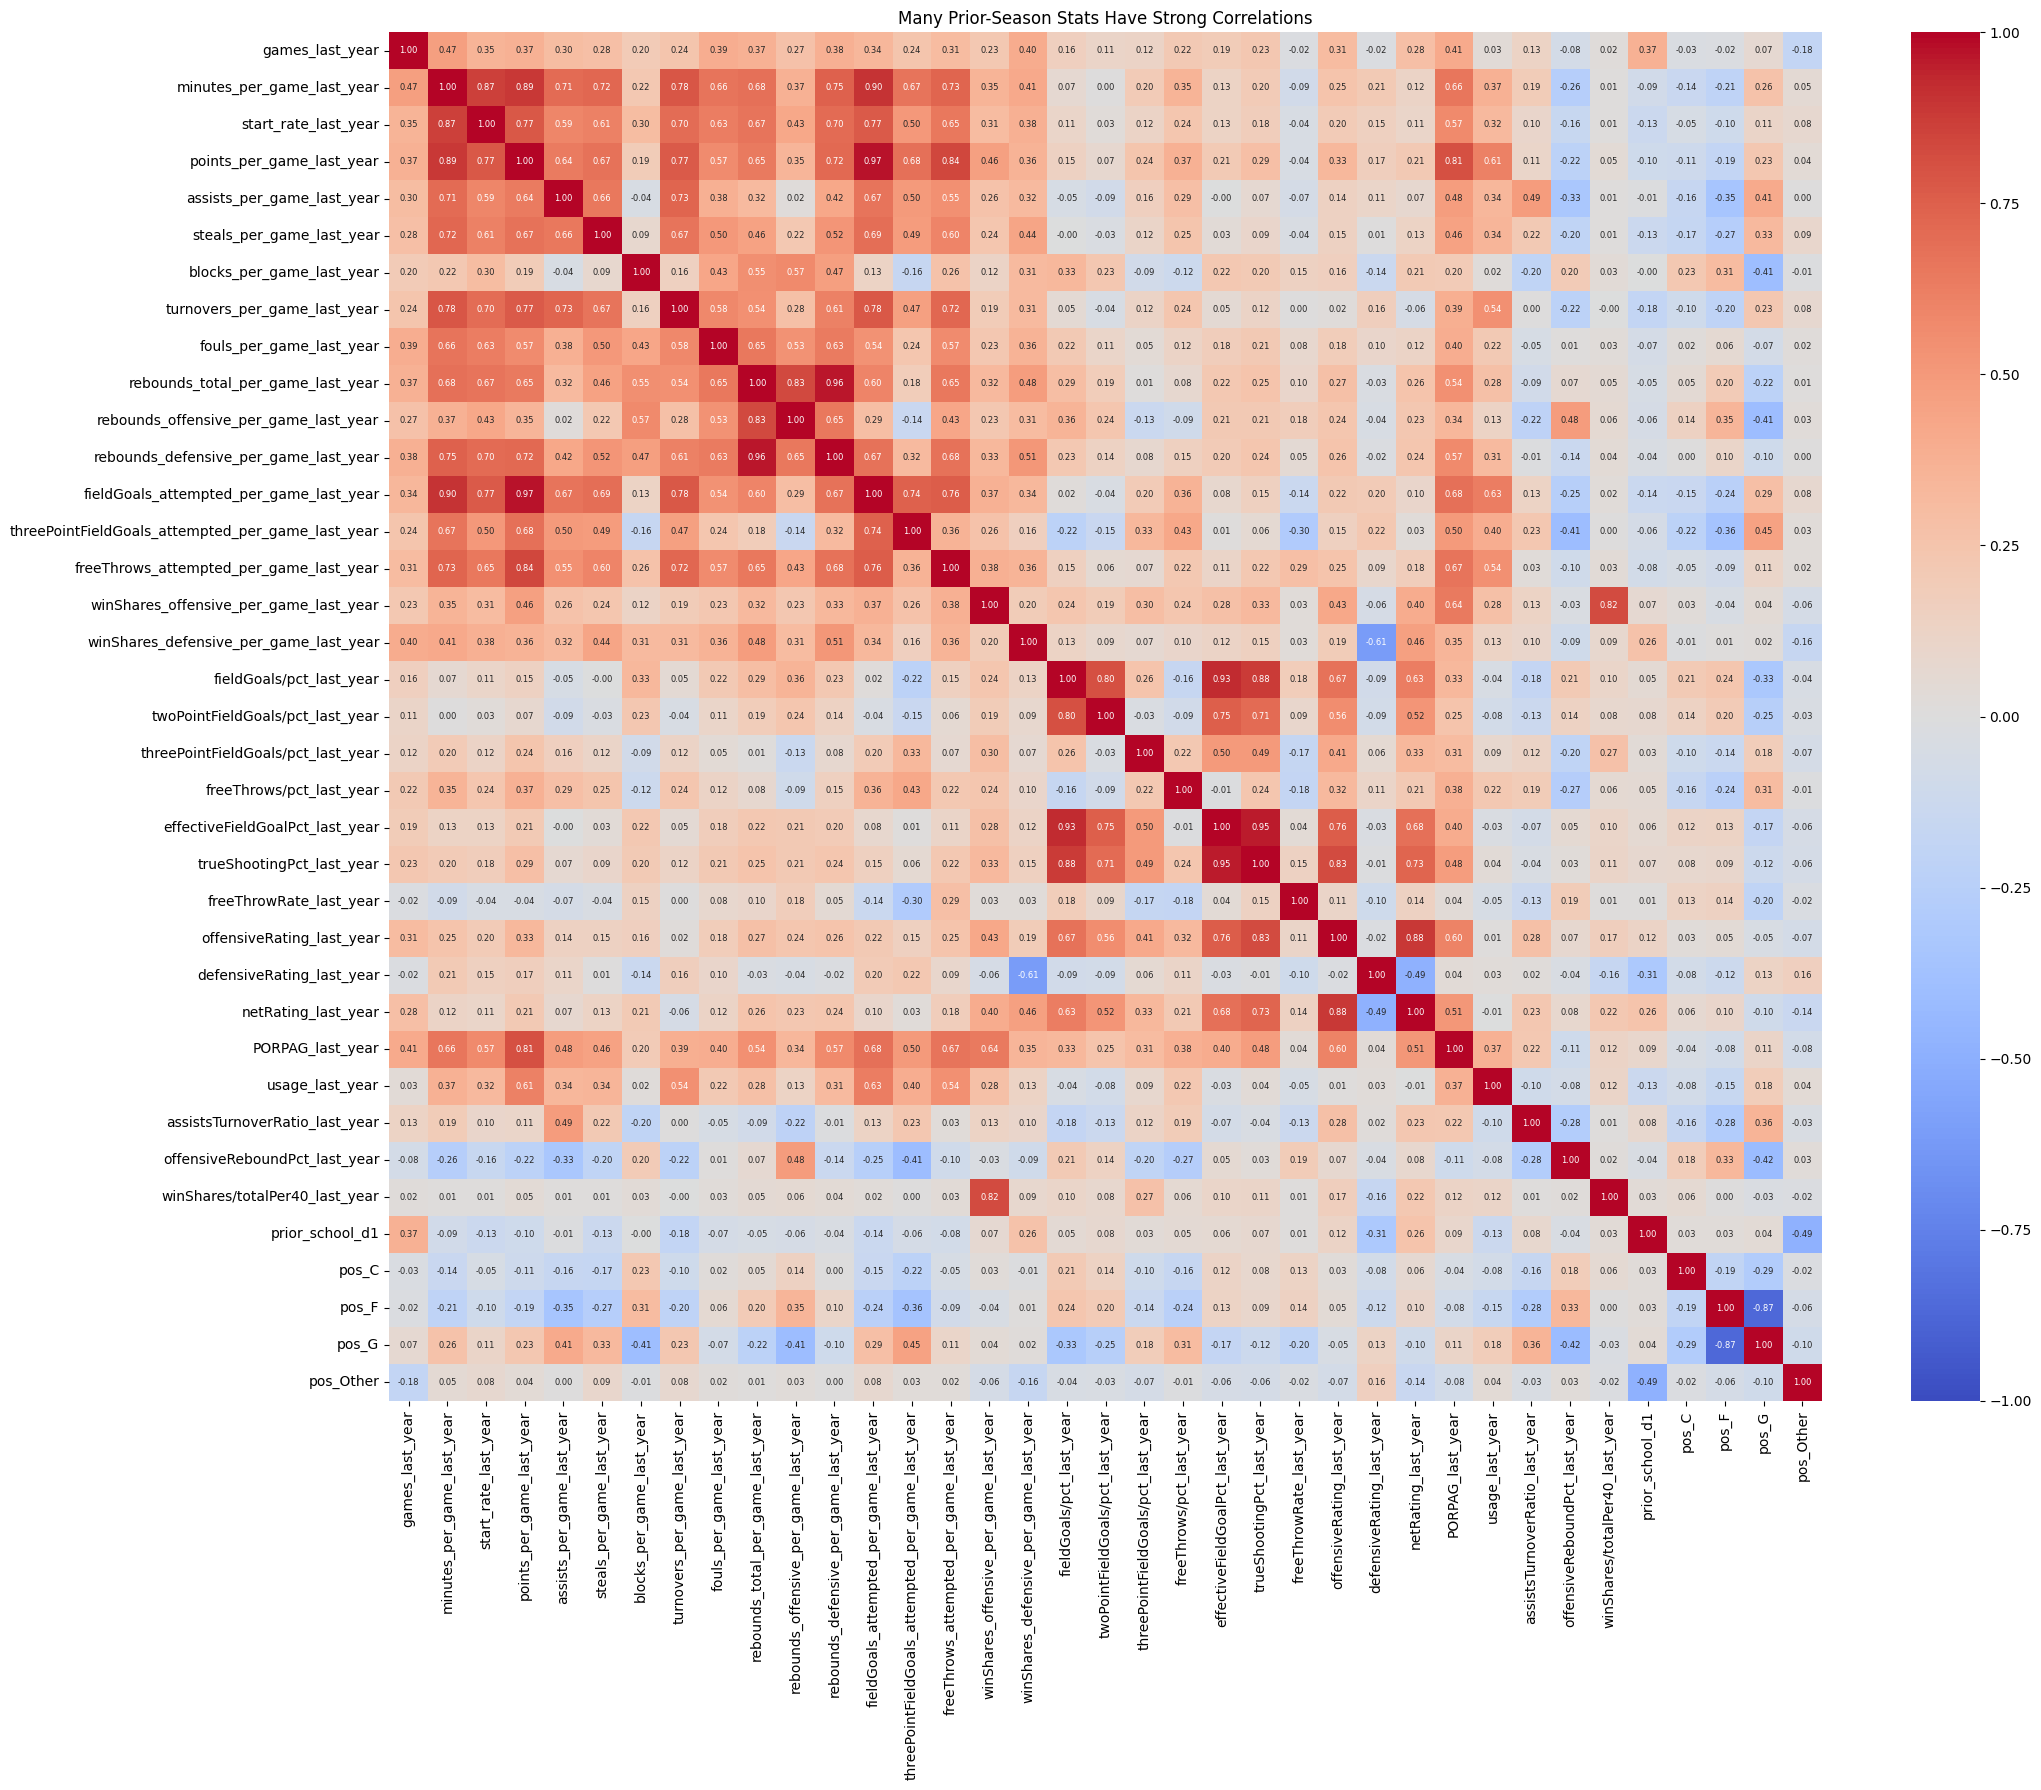

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = transfers_d1[candidate_features].corr() # Correlations of possible feature variables

plt.figure(figsize=(22, 18)) # Large plot to fit numbers
sns.heatmap(corr, annot=True, fmt='.2f', annot_kws={"size": 6}, cmap='coolwarm', center=0, vmin=-1, vmax=1) # Plot correlation
plt.title('Many Prior-Season Stats Have Strong Correlations')
plt.tight_layout()
plt.show()

The correlation matrix shows that many of our 37 prior-season features have strong correlations and overlap with each other. Some of the strongest relationships include points per game and field goal attempts per game (0.97), total and defensive rebounds per game (0.97), effective field goal percentage and true shooting percentage (0.95), field goal percentage and effective field goal percentage (0.93), and minutes per game and field goal attempts per game (0.90). Most other pairs are only weakly or moderately correlated. Because some features overlap with each other, we will probably be able to use a smaller set of features for our predictions versus all 37.

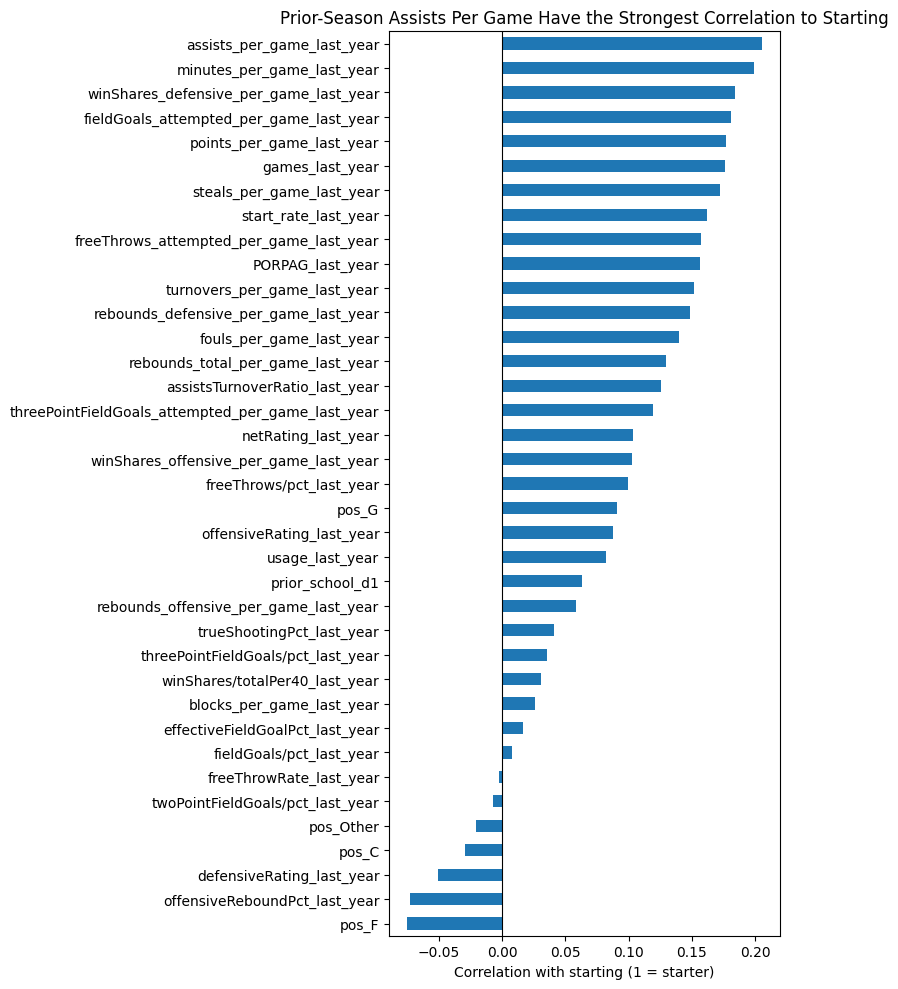

assists_per_game_last_year                 0.206
minutes_per_game_last_year                 0.199
winShares_defensive_per_game_last_year     0.184
fieldGoals_attempted_per_game_last_year    0.181
points_per_game_last_year                  0.177
games_last_year                            0.176
steals_per_game_last_year                  0.173
start_rate_last_year                       0.162
freeThrows_attempted_per_game_last_year    0.157
PORPAG_last_year                           0.156
Name: starter, dtype: float64


In [33]:
target_corr = transfers_d1[candidate_features + ["starter"]].corr()["starter"].drop("starter").sort_values() # Correlation with starter

plt.figure(figsize=(8, 10))
target_corr.plot.barh() # Horizontal bar plot
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with starting (1 = starter)")
plt.title("Prior-Season Assists Per Game Have the Strongest Correlation to Starting")
plt.tight_layout()
plt.show()

print(target_corr.sort_values(key=abs, ascending=False).head(10).round(3))

This horizontal bar plot shows the correlation between a prior-season feature and whether a player started more than half of his games at his new school. All of the correlations are pretty weak, and the strongest is assists per game at 0.206, then minutes per game at 0.199, defensive win shares per game at 0.184, field goal attempts per game at 0.181, points per game at 0.177, and games played at 0.176. Most of the top features measure how much a player played or how much of the offense he handled, which makes sense, since players who were on the floor and involved the most last year are more likely to start at their next school. Efficiency stats like field goal percentage, effective field goal percentage, and true shooting percentage are close to zero, so how efficiently a player scored matters much less that we would have expected. The only meaningful negative correlations are offensive rebound percentage (about -0.07), defensive rating (about -0.05), and the forward and center position groups (about -0.08 and -0.03), although these are all small.

### Target & Seasonality Overview (Starters vs. Non-Starters)

,season,total_transfers,starters,starter_rate,espn_ranked_count,starter_rate_pct
0,2021,411,212,0.515815,0,51.6
1,2022,807,447,0.553903,92,55.4
2,2023,801,437,0.545568,96,54.6
3,2024,924,490,0.530303,94,53.0
4,2025,1176,643,0.546769,98,54.7
5,2026,1390,756,0.543885,93,54.4


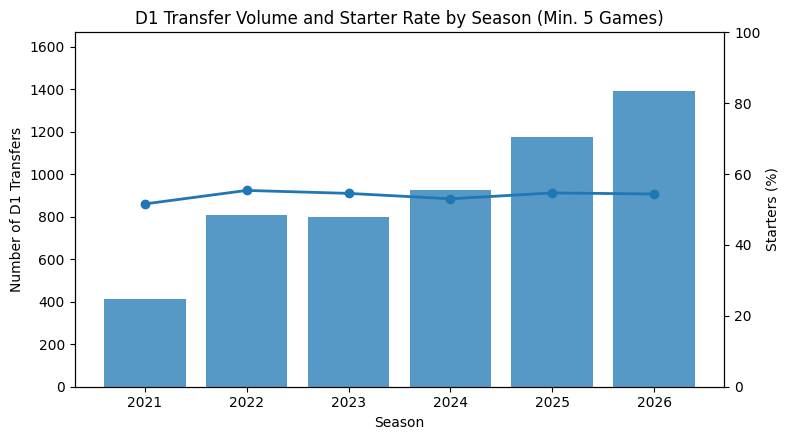

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Overall starter rate and breakdown by season
season_summary = (
    transfers_d1.groupby("season")
    .agg(
        total_transfers=("starter", "count"),
        starters=("starter", "sum"),
        starter_rate=("starter", "mean"),
        espn_ranked_count=("espn_preseason_rank", lambda s: s.notna().sum()),
    )
    .reset_index()
)
season_summary["starter_rate_pct"] = (season_summary["starter_rate"] * 100).round(1)
display(season_summary)

# Plot transfer volume and starter rate across seasons
fig, ax1 = plt.subplots(figsize=(8, 4.5))

bars = ax1.bar(
    season_summary["season"].astype(str),
    season_summary["total_transfers"],
    alpha=0.75,
    label="D1 Transfers (n)",
)
ax1.set_xlabel("Season")
ax1.set_ylabel("Number of D1 Transfers")
ax1.set_ylim(0, season_summary["total_transfers"].max() * 1.2)

ax2 = ax1.twinx()
line = ax2.plot(
    season_summary["season"].astype(str),
    season_summary["starter_rate"] * 100,
    marker="o",
    linewidth=2,
    label="Starter Rate (%)",
)
ax2.set_ylabel("Starters (%)")
ax2.set_ylim(0, 100)

plt.title("D1 Transfer Volume and Starter Rate by Season (Min. 5 Games)")
fig.tight_layout()
plt.show()

This step aggregates transfers_d1 by season to compute total transfer counts, starter counts, starter percentages, and how many transfers in each season match to an ESPN preseason ranking. The accompanying dual axis chart pairs blue bar counts of Division I transfer volume (left axis, 0 to 1,600) with a connected line showing starter percentage (right axis, 0% to 100%) across the 2021 through 2026 seasons, helping verify whether target balance or transfer volume shifts substantially over time. As shown in the table and graph, transfer volume more than triples across the sample period starting at 411 transfers (212 starters) in 2021, nearly doubling to 807 (447 starters) in 2022 and 801 (437 starters) in 2023, rising to 924 (490 starters) in 2024, and climbing sharply to 1,176 (643 starters) in 2025 and 1,390 (756 starters) in 2026, while ESPN ranked matches remain steady at 92 to 98 players per season from 2022 through 2026 (with 0 in 2021). Despite this sharp growth in transfer volume, the starter rate line remains remarkably flat just above 50% in every season starting at 51.6% in 2021, peaking at 55.4% in 2022, and holding steady at 54.6% in 2023, 53.0% in 2024, 54.7% in 2025, and 54.4% in 2026 confirming that target balance stays consistent over time even as later seasons account for a larger share of total transfers.

### Prior Division, Position Group, and ESPN Preseason Rank vs. Starting

Starter rate by prior school D1 status (1 = D1, 0 = Non-D1):


,count,starter_rate
prior_school_d1,,
0,141,0.348
1,5368,0.547



Starter rate by grouped position:


,count,starter_rate
position_group,,
G,3128,0.581
F,2014,0.493
C,329,0.483
Other,38,0.421


,rank_tier,count,starter_rate,starter_rate_pct
0,Top 25,121,0.892562,89.3
1,26–50,120,0.766667,76.7
2,51–100,232,0.724138,72.4
3,101+,0,NaN,NaN


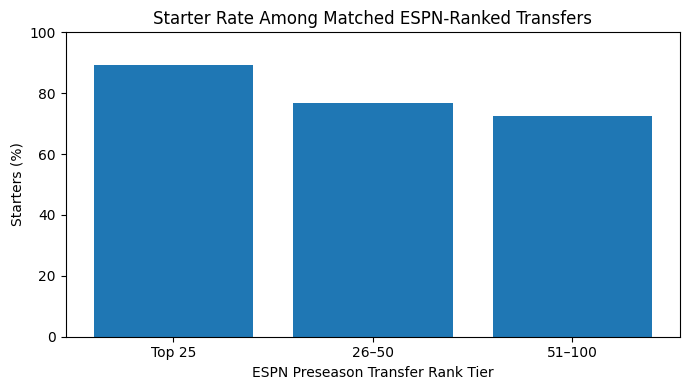

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [35]:
# Compare starter rates by prior school D1 status and position group
print("Starter rate by prior school D1 status (1 = D1, 0 = Non-D1):")
display(
    transfers_d1.groupby("prior_school_d1")["starter"]
    .agg(count="count", starter_rate="mean")
    .round(3)
)

print("\nStarter rate by grouped position:")
display(
    transfers_d1.groupby("position_group")["starter"]
    .agg(count="count", starter_rate="mean")
    .sort_values("starter_rate", ascending=False)
    .round(3)
)

# For ESPN-ranked transfers, bucket rank into tiers to inspect starter rate
ranked_df = transfers_d1[transfers_d1["espn_preseason_rank"].notna()].copy()
ranked_df["rank_tier"] = pd.cut(
    ranked_df["espn_preseason_rank"],
    bins=[0, 25, 50, 100, 500],
    labels=["Top 25", "26–50", "51–100", "101+"],
)

rank_summary = (
    ranked_df.groupby("rank_tier", observed=False)["starter"]
    .agg(count="count", starter_rate="mean")
    .reset_index()
)
rank_summary["starter_rate_pct"] = (rank_summary["starter_rate"] * 100).round(1)
display(rank_summary)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rank_summary["rank_tier"].astype(str), rank_summary["starter_rate_pct"])
ax.set_xlabel("ESPN Preseason Transfer Rank Tier")
ax.set_ylabel("Starters (%)")
ax.set_ylim(0, 100)
ax.set_title("Starter Rate Among Matched ESPN-Ranked Transfers")
plt.tight_layout()
plt.show()

This block evaluates how starter rates vary across three contextual groupings: prior-school division status (prior_school_d1), grouped playing positions (position_group), and tiered buckets of espn_preseason_rank (Top 25, 26-50, 51-100, 101+) among players with ESPN preseason rankings. Transfers coming from Division I programs (prior_school_d1 = 1, n = 5,368) start at a substantially higher rate (54.7%) than those arriving from non-D1 programs (prior_school_d1 = 0, n = 141, 34.8%), while guards (G, n = 3,128) start at a higher rate (58.1%) than forwards (F, n = 2,014, 49.3%), centers (C, n = 329, 48.3%), and Other (n = 38, 42.1%). As shown in the table and bar chart of matched ESPN-ranked transfers (with Starters (%) from 0 to 100 on the vertical axis), starter rates step down monotonically as preseason rank gets less prestigious, moving from 89.3% in Top 25 (n = 121) to 76.7% in 26-50 (n = 120) and 72.4% in 51-100 (n = 232), with 0 players (NaN) in the 101+ tier because the 2022-2026 ESPN transfer rankings included 100 players per class, confirming that higher-ranked incoming transfers start noticeably more often and justifying the inclusion of these context features.

### Numeric Feature Distributions & Skewness (Log / IHS / Parabolic Check)

Top 12 most skewed numeric candidate features:


,mean,std,median,skew,min,max
winShares/totalPer40_last_year,0.090,0.554,0.089,71.038,-2.00,40.444
winShares_offensive_per_game_last_year,0.025,0.052,0.018,33.713,-0.20,3.000
pos_Other,0.007,0.083,0.000,11.919,0.00,1.000
prior_school_d1,0.974,0.158,1.000,-6.010,0.00,1.000
freeThrowRate_last_year,34.320,25.089,30.600,4.195,0.00,400.000
pos_C,0.060,0.237,0.000,3.717,0.00,1.000
assistsTurnoverRatio_last_year,1.044,0.723,0.950,2.890,0.00,12.000
blocks_per_game_last_year,0.327,0.417,0.194,2.751,0.00,4.094
defensiveRating_last_year,105.638,10.931,105.400,1.820,-7.90,245.100
winShares_defensive_per_game_last_year,0.021,0.021,0.019,-1.698,-0.25,0.104


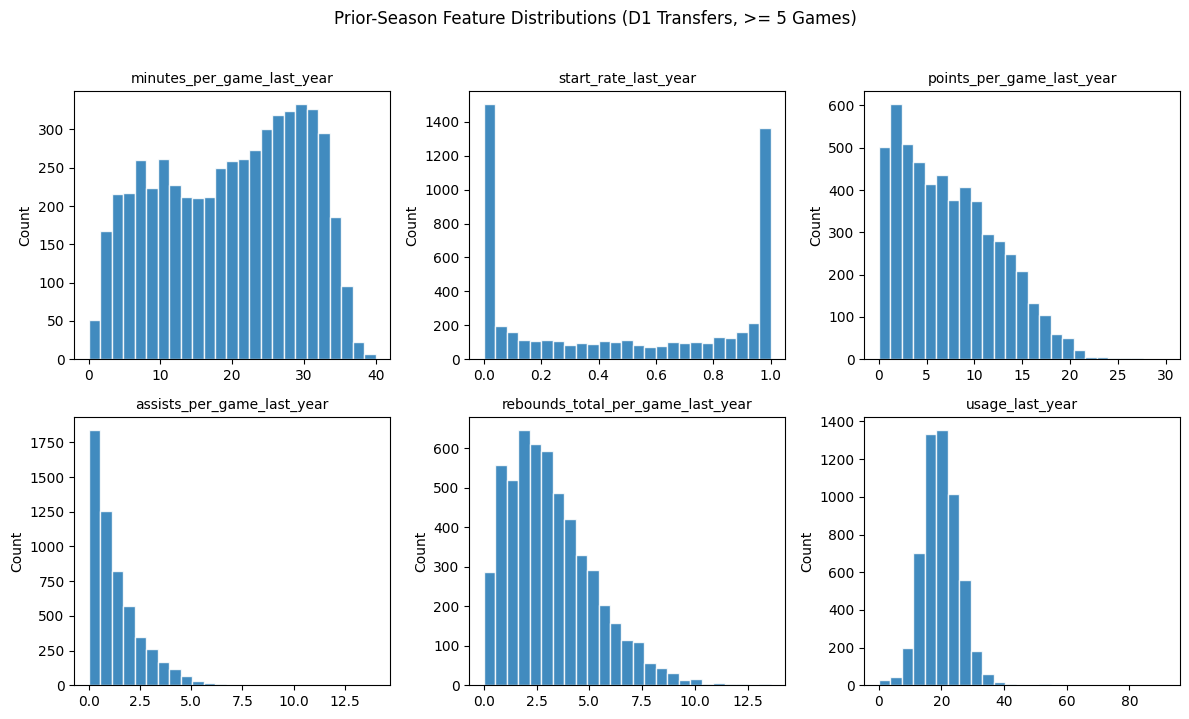

In [36]:
numeric_candidates = [
    c for c in candidate_features if pd.api.types.is_numeric_dtype(transfers_d1[c])
]

dist_summary = pd.DataFrame(
    {
        "mean": transfers_d1[numeric_candidates].mean(),
        "std": transfers_d1[numeric_candidates].std(),
        "median": transfers_d1[numeric_candidates].median(),
        "skew": transfers_d1[numeric_candidates].skew(),
        "min": transfers_d1[numeric_candidates].min(),
        "max": transfers_d1[numeric_candidates].max(),
    }
).round(3)

print("Top 12 most skewed numeric candidate features:")
display(dist_summary.reindex(dist_summary["skew"].abs().sort_values(ascending=False).index).head(12))

# Histograms of key prior-season workload & production features
key_cols = [
    "minutes_per_game_last_year",
    "start_rate_last_year",
    "points_per_game_last_year",
    "assists_per_game_last_year",
    "rebounds_total_per_game_last_year",
    "usage_last_year",
]
available_key_cols = [c for c in key_cols if c in transfers_d1.columns]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()

for i, col in enumerate(available_key_cols):
    axes[i].hist(transfers_d1[col].dropna(), bins=25, edgecolor="white", alpha=0.85)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("Count")

plt.suptitle("Prior-Season Feature Distributions (D1 Transfers, >= 5 Games)", y=1.02)
plt.tight_layout()
plt.show()

This step computes summary statistics (mean, standard deviation, median, skewness, minimum, and maximum) across numeric features in candidate_features, ranks them by absolute skewness, and plots six histograms for core workload and production metrics (minutes_per_game_last_year, start_rate_last_year, points_per_game_last_year, assists_per_game_last_year, rebounds_total_per_game_last_year, and usage_last_year). Skewness is highest in outlier-heavy rate and binary metrics such as winShares/totalPer40_last_year (71.038), winShares_offensive_per_game_last_year (33.713), pos_Other (11.919), prior_school_d1 (-6.010), and freeThrowRate_last_year (4.195). Visually, the histograms show left skew for minutes per game (peaking around 28 to 32 minutes), U-shaped spikes near 0.0 and 1.0 for prior start rate, right skew for points, assists, and rebounds per game, and a roughly bell-shaped distribution for usage around 18% to 22%, motivating median imputation, feature scaling, and potential non-linear transforms.

### Starter vs. Non-Starter Means & Correlation Heatmap

,non_starter_mean,starter_mean,diff_starter_minus_non,abs_diff,corr_with_starter
assists_per_game_last_year,1.035,1.539,0.504,0.504,0.206
minutes_per_game_last_year,17.622,21.550,3.928,3.928,0.199
winShares_defensive_per_game_last_year,0.017,0.024,0.008,0.008,0.184
fieldGoals_attempted_per_game_last_year,5.239,6.682,1.443,1.443,0.181
points_per_game_last_year,6.415,8.231,1.816,1.816,0.177
games_last_year,22.084,25.555,3.471,3.471,0.176
steals_per_game_last_year,0.560,0.733,0.174,0.174,0.173
start_rate_last_year,0.415,0.549,0.133,0.133,0.162
freeThrows_attempted_per_game_last_year,1.665,2.156,0.492,0.492,0.157
PORPAG_last_year,0.902,1.299,0.396,0.396,0.156


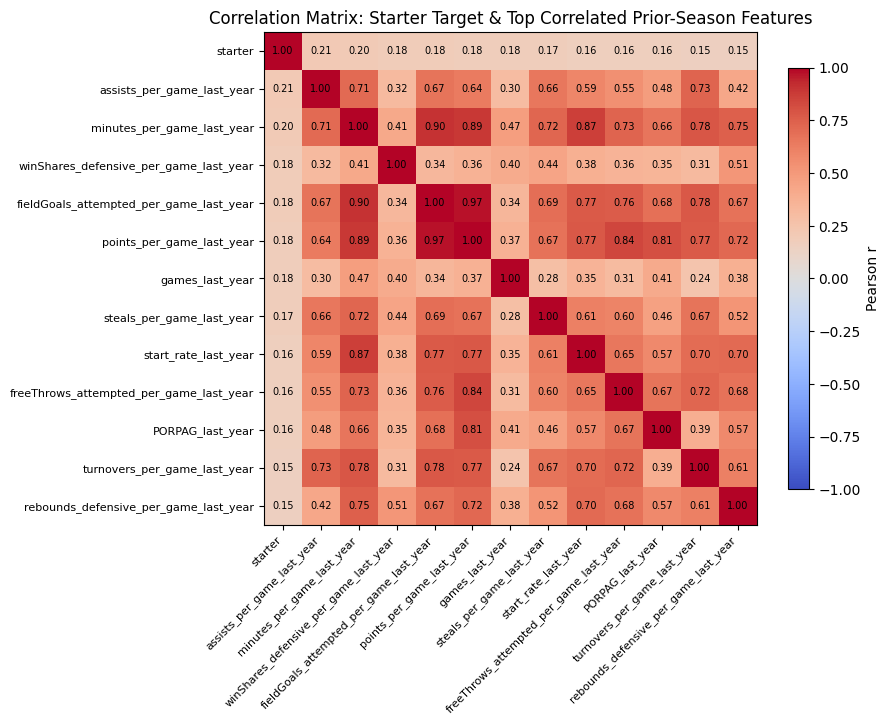

In [37]:
# Mean difference between starters and non-starters across numeric candidate features
means_by_starter = transfers_d1.groupby("starter")[numeric_candidates].mean().T
means_by_starter.columns = ["non_starter_mean", "starter_mean"]
means_by_starter["diff_starter_minus_non"] = (
    means_by_starter["starter_mean"] - means_by_starter["non_starter_mean"]
)
means_by_starter["abs_diff"] = means_by_starter["diff_starter_minus_non"].abs()

# Correlation with target ('starter')
target_corr = transfers_d1[numeric_candidates].apply(
    lambda s: s.corr(transfers_d1["starter"])
)
means_by_starter["corr_with_starter"] = target_corr

top_corr_cols = (
    target_corr.abs().sort_values(ascending=False).head(12).index.tolist()
)
display(means_by_starter.loc[top_corr_cols].round(3))

# Correlation matrix among top target-correlated features + starter
corr_matrix = transfers_d1[["starter"] + top_corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(corr_matrix.columns, fontsize=8)

for r in range(len(corr_matrix.index)):
    for c in range(len(corr_matrix.columns)):
        val = corr_matrix.iloc[r, c]
        ax.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=7, color="black")

fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation Matrix: Starter Target & Top Correlated Prior-Season Features")
plt.tight_layout()
plt.show()

This block compares average feature values between starters (starter = 1) and non-starters (starter = 0), computes their mean differences and Pearson correlations with starter, and plots a correlation matrix for starter and the top 12 predictors. Future starters average higher values across every top workload and scoring metric, led by assists_per_game_last_year (1.539 vs. 1.035, r = 0.206), minutes_per_game_last_year (21.550 vs. 17.622, r = 0.199), winShares_defensive_per_game_last_year (r = 0.184), fieldGoals_attempted_per_game_last_year (r = 0.181), points_per_game_last_year (8.231 vs. 6.415, r = 0.177), and games_last_year (25.555 vs. 22.084, r = 0.176). In the heatmap, target correlations remain modest across the top row (r = 0.15 to 0.21), whereas strong red blocks reveal heavy collinearity among playing-time and volume features such as points_per_game_last_year and fieldGoals_attempted_per_game_last_year (r = 0.97) or minutes_per_game_last_year and start_rate_last_year (r = 0.87), motivating feature selection to reduce redundancy.

# **Build models**

### Split into training and test data

In [38]:
test_season = 2026 # Make the most recent season the test set

# Calculate % of test season rows vs all rows
rows_total = len(transfers_d1)
rows_test = (transfers_d1["season"] == test_season).sum()
rows_train = (transfers_d1["season"] != test_season).sum()

print(f"2026 rows: {rows_test} ({rows_test / rows_total:.1%})")
print(f"Other years rows: {rows_train} ({rows_train / rows_total:.1%})")

2026 rows: 1390 (25.2%)
Other years rows: 4119 (74.8%)


In [39]:
train = transfers_d1[transfers_d1["season"] < test_season] # Train on the 2021 to 2025 transfers
test = transfers_d1[transfers_d1["season"] == test_season] # Test on the 2026 transfers (we do not touch these until the Evaluate models section)

X_train, y_train = train[candidate_features], train["starter"]
X_test, y_test = test[candidate_features], test["starter"]
groups_train = train["athleteId"] # Kew rows with the same player id together

print(f"Training transfers: {len(train)} (seasons {train['season'].min()} to {train['season'].max()}), starters: {y_train.mean():.1%}")
print(f"Test transfers: {len(test)} (season {test_season}), starters: {y_test.mean():.1%}")

Training transfers: 4119 (seasons 2021 to 2025), starters: 54.1%
Test transfers: 1390 (season 2026), starters: 54.4%


We decided to do a time-based training/test set data split because the same player could appear in both the training and testing set since some players transfer multiple times, which could give a falsely increased test accuracy score and it matches closely to a standard 75/25 split. We made the 2026 season be the test set and trained on the 2021 to 2025 transfers. This is also a more similar process to how a coach would use the model, predicting a new class of transfers from past classes. The training set has 4,119 transfers with 54.1% starting at their new school and the test set has 1,390 transfers with 54.4% starters. The similar percentage of starters will be helpful when comparing training and testing accuracy.

### Feature selection

Before building our models, we need to choose which of the 37 prior-season features to use. Many of them overlap (for example, three different shooting percentages), and our goal is to narrow down the stats that a coach needs to focus on when choosing which transferes to pursue. We will determine our features only using the training data to ensure the test data doesn't influence feature selection choices and impact test accuracy. We will use one feature selection using lasso logistic regression for the different models we build and test. Since our research question asks which prior-season stats best predict a starting role, we want to use one list of features to compare each model fairly (if each model picked its own features, it would be hard to tell whether the accuracy differences came from the model or the feature selection). WWe chose the lasso because it reduces the number of features by pushing the weights of unhelpful features to exactly zero. Since the lasso is a linear model, the kNN or **the __** might favor different features. To check this, we fit every model twice, once on all 37 features and once on the selected features.

**Cross-validation**

In [40]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

We set up the cross-validation first so that feature selection and the models use the same folds. The folds keep every row for the same player together and keep the share of starters similar across folds. We used a stratified group KFold since we are predicting a binary variable (starter or not) and some players appear more than once in the data. Stratifying keeps about 54% starters in every fold, and grouping by player ensures that other transfer rows from the same player aren't included in both the testing and training folds. We are using cross-validation to choose our model parameters, such as the lasso penalty and the number of features, without using the 2026 test set. We will split the training data into 5 folds, train on 4, validate on 1, and rotate through all 5. This makes sure every player is used once for validation and we can average the scores.

**Selecting the lasso penalty**

In [41]:
lasso_selector_pipeline = make_pipeline(
    SimpleImputer(strategy="median"), # Fill missing values with the training median
    StandardScaler(), # Put the features on the same scale
    LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=1000, random_state=0) # l1_ratio=1 is the lasso (L1) penalty
)

penalty_grid = {"logisticregression__C": list(np.logspace(-3, 1, 20))} # Smaller C = stronger penalty (used for logistic)
search = GridSearchCV( # Tests each candidate penalty and selects the highest accuracy
    lasso_selector_pipeline,
    penalty_grid,
    cv=cv,
    scoring={"accuracy": "accuracy", "neg_log_loss": "neg_log_loss"},
    refit="neg_log_loss") # Choose the penalty by log loss

search.fit(X_train, y_train, groups=groups_train) # Fit search

best_C = search.best_params_["logisticregression__C"] # The chosen penalty strength
penalty_table = pd.DataFrame({"C": penalty_grid["logisticregression__C"],
                              "CV accuracy": search.cv_results_["mean_test_accuracy"],
                              "CV log loss": -search.cv_results_["mean_test_neg_log_loss"]}) # Flip the sign back so lower is better
print(penalty_table.round(4).to_string(index=False))
print(f"\nChosen C: {best_C:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_

      C  CV accuracy  CV log loss
 0.0010       0.6137       0.6557
 0.0016       0.6184       0.6543
 0.0026       0.6189       0.6535
 0.0043       0.6191       0.6533
 0.0070       0.6186       0.6534
 0.0113       0.6168       0.6536
 0.0183       0.6183       0.6539
 0.0298       0.6181       0.6542
 0.0483       0.6171       0.6545
 0.0785       0.6157       0.6548
 0.1274       0.6147       0.6550
 0.2069       0.6130       0.6552
 0.3360       0.6130       0.6553
 0.5456       0.6137       0.6554
 0.8859       0.6145       0.6555
 1.4384       0.6147       0.6556
 2.3357       0.6142       0.6557
 3.7927       0.6147       0.6558
 6.1585       0.6154       0.6558
10.0000       0.6157       0.6559

Chosen C: 0.0043


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


Based on our correlation plot of potential feature variables, we saw that 5 feature pairs had particularly strong correlations, meaning they provide similar information to the model. As a result, we will use lasso to shrink the weights of redundant features to zero and keep a smaller set of the most useful ones. We used lasso (L1) instead of ridge (L2) because we want to identify which prior-season stats are the most important, and lasso shrinks the weights of unhelpful features to zero, which helps us narrow our features, whereas ridge keeps every feature in the model with a smaller weight.

We chose the lasso penalty by cross-validation on the training data. Accuracy is almost the same for every `C` from about 0.01 to 10 (between 61.1% and 61.8%), so it cannot tell us which penalty is best. We chose the best penalty by looking at the lowest log loss, which measures how good the predicted probabilities are by taking into account the confident of predictions. Log loss is lowest for `C` between about 0.05 and 0.08 (0.653). It gets worse for stronger penalties (a smaller `C` is a stronger penalty) and rises only slightly for weaker ones (0.657 at `C` = 10). The strongest penalties (`C` of 0.0026 or less) drop every feature, so the model predicts the same outcome for every player and its accuracy falls to 45.9%. We use the chosen `C` of 0.0785 because it minimizes log loss, which has an accuracy of 61.5%.

**Determining number of features**

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_

                         CV accuracy
Number of features kept             
5                              0.616
8                              0.609
10                             0.615
15                             0.617
20                             0.615
25                             0.619
37                             0.619


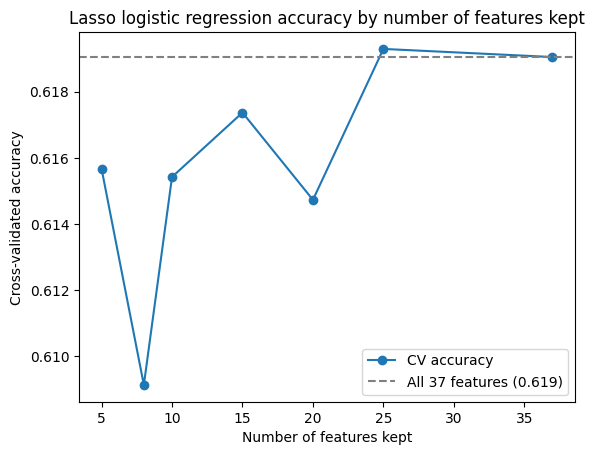

In [42]:
from sklearn.feature_selection import SelectFromModel

num_features = [5, 8, 10, 15, 20, 25, 37]

# Logistic regression with chosen lasso penalty
lasso_model = LogisticRegression(l1_ratio=1, solver="liblinear", C=best_C, max_iter=1000, random_state=0)

baseline_accuracy = cross_val_score(
    make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clone(lasso_model)), # Build the model
    X_train, y_train, groups=groups_train, cv=cv, scoring="accuracy").mean() # Averages accuracies of all folds into the mean

line = []
for k in num_features:
    lasso_select = SelectFromModel(clone(lasso_model), max_features=k, threshold=-np.inf) # Keep the k features with the largest lasso weights
    pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), lasso_select, clone(lasso_model)) # Build each model
    scores = cross_val_score(pipeline, X_train, y_train, groups=groups_train, cv=cv, scoring="accuracy") # Collect model scores
    line.append(scores.mean()) # Add mean to line

line_table = pd.DataFrame({"CV accuracy": line}, index=num_features) # Build a table showing accuracy by number of features kept
line_table.index.name = "Number of features kept"
print(line_table.round(3))

line_table.plot(marker="o", legend=False) # Plot accuracy line
plt.axhline(baseline_accuracy, color="gray", linestyle="--", label=f"All 37 features ({baseline_accuracy:.3f})") # Plot baseline
plt.ylabel("Cross-validated accuracy")
plt.title("Lasso logistic regression accuracy by number of features kept")
plt.legend()
plt.show()

Cross-validated accuracy is almost the same no matter how many features the lasso keeps. The graph looks dramatic only because the y-axis is zoomed in so far that it spans about 61.5% to 61.7%. Keeping only 5 or 10 features gives about 61.7% accuracy (the two differ by less than 0.1 percentage points), and keeping 8, 15, 20, 25, or all 37 gives about 61.5%. The highest accuracy is at 10 features, but the difference between the highest and lowest accuracy is only about 0.3 percentage points, which could be noise from the different fold splits. This shows that a lot of the 37 features don't actually add more accuracy to the model, and we can use a much smaller set without losing accuracy. Since a smaller set of stats is easier for a coach to use, we choose a small set of features (about 10) for our final models.

**Resampling to see how often features are kept**

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_

games_last_year                                      1.0
minutes_per_game_last_year                           1.0
start_rate_last_year                                 1.0
points_per_game_last_year                            1.0
assists_per_game_last_year                           1.0
steals_per_game_last_year                            1.0
blocks_per_game_last_year                            1.0
turnovers_per_game_last_year                         1.0
fouls_per_game_last_year                             1.0
rebounds_total_per_game_last_year                    1.0
rebounds_offensive_per_game_last_year                1.0
rebounds_defensive_per_game_last_year                1.0
fieldGoals_attempted_per_game_last_year              1.0
threePointFieldGoals_attempted_per_game_last_year    1.0
freeThrows_attempted_per_game_last_year              1.0
dtype: float64


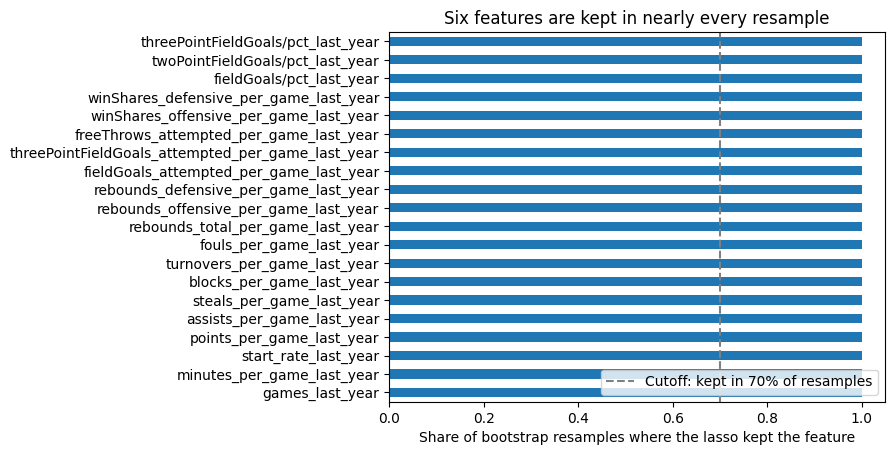

In [43]:
# Stability selection: refit the lasso on 100 bootstrap resamples of the training data and count how often each feature is kept
from sklearn.utils import resample

X_imputed = SimpleImputer(strategy="median").fit_transform(X_train) # Impute
X_scaled = StandardScaler().fit_transform(X_imputed) # Scale
n_boot = 100 # Use 100 bootstrap resamples
kept_counts = pd.Series(0, index=candidate_features) # Keep track of what columns belong to what features

for i in range(n_boot):
    Xi, yi = resample(X_scaled, y_train.values, random_state=i) # Bootstrap sample
    lasso_i = LogisticRegression(l1_ratio=1, solver="liblinear", C=best_C, max_iter=1000, random_state=0).fit(Xi, yi) # Build the lasso model for each sample
    kept_counts += (lasso_i.coef_[0] != 0) # True if lasso keeps the feature

selection_rate = (kept_counts / n_boot).sort_values(ascending=False)
print(selection_rate.round(2).head(15))

selection_rate.head(20).sort_values().plot.barh()
plt.axvline(0.7, color="gray", linestyle="--", label="Cutoff: kept in 70% of resamples")
plt.xlabel("Share of bootstrap resamples where the lasso kept the feature")
plt.title("Six features are kept in nearly every resample")
plt.legend(loc="lower right")
plt.show()

Because the features that the lasso sends to 0 can vary as the training data changes, we refit it on 100 bootstrap resamples of the training data and counted how often each feature is kept. Games played last year and defensive win shares per game were kept in almost all resamples. Assist to turnover ratio and assists per game were kept in 98% of resamples, effective field goal percentage in 97%, and net rating in 95%. Features that are kept in nearly every resample are more reliable predictors since their influence on predicting a starting role doesn't depend on which players happen to be in the sample. This shows which stats consistently carry information about starting.

**Final feature set**

In [44]:
selected_features = list(selection_rate[selection_rate >= 0.7].index) # Features kept in at least 70% of resamples
print(f"Selected {len(selected_features)} features:")
for name in selected_features:
    print(f"  {name} (kept in {selection_rate[name]:.0%} of resamples)")

Selected 37 features:
  games_last_year (kept in 100% of resamples)
  minutes_per_game_last_year (kept in 100% of resamples)
  start_rate_last_year (kept in 100% of resamples)
  points_per_game_last_year (kept in 100% of resamples)
  assists_per_game_last_year (kept in 100% of resamples)
  steals_per_game_last_year (kept in 100% of resamples)
  blocks_per_game_last_year (kept in 100% of resamples)
  turnovers_per_game_last_year (kept in 100% of resamples)
  fouls_per_game_last_year (kept in 100% of resamples)
  rebounds_total_per_game_last_year (kept in 100% of resamples)
  rebounds_offensive_per_game_last_year (kept in 100% of resamples)
  rebounds_defensive_per_game_last_year (kept in 100% of resamples)
  fieldGoals_attempted_per_game_last_year (kept in 100% of resamples)
  threePointFieldGoals_attempted_per_game_last_year (kept in 100% of resamples)
  freeThrows_attempted_per_game_last_year (kept in 100% of resamples)
  winShares_offensive_per_game_last_year (kept in 100% of resampl

Because we want a small set of the most important features to give coaches manageable insights for future recruiting (around 10), we keep the features that were kept in 70% or more of the resamples. This gives us 12 features that the lasso consistently kept instead of setting them to zero. Every remaining feature, such as field goal attempts per game, three-point percentage, and free throw percentage, was kept in fewer than 70% of resamples, so we drop them, since the lasso does not reliably find them useful. Dropping them also doesn't impact accuracy (as discussed in the section above), so using more of the 37 features does not make the model more accurate on this dataset.

### Setting up a baseline

In [45]:
feature_sets = {"all 37 features": candidate_features,
                f"{len(selected_features)} selected features": selected_features} # Want to fit every model on both sets of features
scoring = {"accuracy": "accuracy", "neg_log_loss": "neg_log_loss"}
cv_results = {} # Cross-validated scores for each model's best settings

baseline_acc = y_train.mean() # Share of starters
cv_results["Baseline: always predict starter"] = {"accuracy": baseline_acc}
print(f"Baseline accuracy: {baseline_acc:.1%}")

Baseline accuracy: 54.1%


We use accuracy as our main metric because our outcome is a yes/no label (starter or not), and accuracy represents the percentage of players the model labels correctly. It also works well here because our classes are fairly balanced, with about 54% of players in the training data being starters, so one high accuracy won't come from one specific class. To judge how good a score is, we compare it to a baseline that always predicts "starter," which would be right 54.1% of the time without using any stats. Our models will only add value their accuracy is greater than 54.1%. We will also use negative log loss with accuracy because it takes into account confidence of probabilities.

### Model 1: k-nearest neighbors

Square root of n: k = 64

all 37 features: k = 108. Validation accuracy: 60.5%.
    Training accuracy Validation accuracy
k                                        
1              100.0%               53.8%
5               72.0%               57.0%
15              65.5%               58.2%
50              62.6%               60.0%
64              62.4%               59.5%
108             61.4%               60.5%
150             61.4%               59.8%
200             61.0%               59.8%


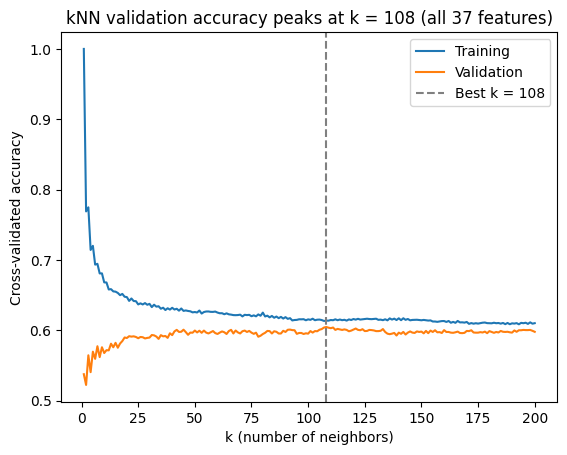


37 selected features: k = 108. Validation accuracy: 60.5%.
    Training accuracy Validation accuracy
k                                        
1              100.0%               53.8%
5               72.0%               57.0%
15              65.5%               58.2%
50              62.6%               60.0%
64              62.4%               59.5%
108             61.4%               60.5%
150             61.4%               59.8%
200             61.0%               59.8%


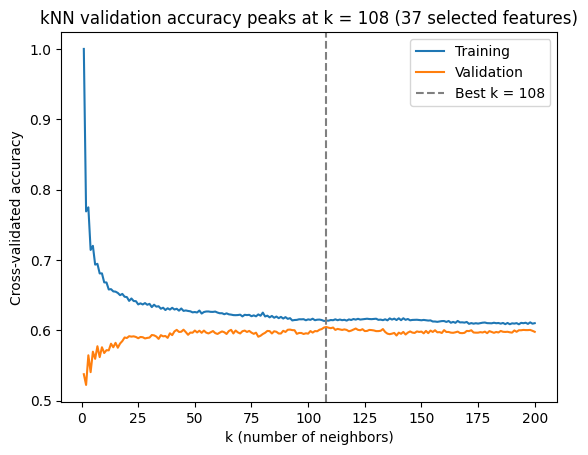

In [46]:
from sklearn.neighbors import KNeighborsClassifier

k_start = round(len(X_train) ** 0.5) # Starting k based on the square root of the number of training rows
print(f"Square root of n: k = {k_start}")

ks = np.arange(1, 201) # Test every k from 1 to 200, which covers a wide range around the square root of n
knn_pipeline = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True), # Fill missing values with the training median and add a column that flags which values were missing
    StandardScaler(), # Standardize every feature so no feature dominates the distance
    KNeighborsClassifier())
knn_grid = {"kneighborsclassifier__n_neighbors": ks}

knn_searches = {} # Empty dictionary to save results
for set_name, features in feature_sets.items(): # Loop through two feature sets
    # For every k, fit on 4 folds and score on the 5th, rotating through all 5 folds, then average
    knn_search = GridSearchCV(knn_pipeline, knn_grid, cv=cv, scoring=scoring, refit="accuracy", return_train_score=True)
    knn_search.fit(X_train[features], y_train, groups=groups_train)
    knn_searches[set_name] = knn_search

    train_accuracy = knn_search.cv_results_["mean_train_accuracy"] # Accuracy on the folds the model was fit on
    valid_accuracy = knn_search.cv_results_["mean_test_accuracy"] # Accuracy on the held-out fold
    i = knn_search.best_index_ # Row of the k with the highest validation accuracy
    k_star = ks[i]
    cv_results[f"kNN ({set_name})"] = {"accuracy": valid_accuracy[i], # Save the model scores
                                       "log loss": -knn_search.cv_results_["mean_test_neg_log_loss"][i]}
    print(f"\n{set_name}: k = {k_star}. Validation accuracy: {valid_accuracy[i]:.1%}.")

    # Accuracy for a few candidate values of k
    candidate_ks = sorted({1, 5, 15, 50, k_start, k_star, 150, 200})
    candidate_table = pd.DataFrame({"Training accuracy": [train_accuracy[k - 1] for k in candidate_ks],
                                    "Validation accuracy": [valid_accuracy[k - 1] for k in candidate_ks]},
                                   index=pd.Index(candidate_ks, name="k"))
    print((candidate_table * 100).round(1).astype(str) + "%")

    plt.plot(ks, train_accuracy, label="Training")
    plt.plot(ks, valid_accuracy, label="Validation")
    plt.axvline(k_star, color="gray", linestyle="--", label=f"Best k = {k_star}")
    plt.xlabel("k (number of neighbors)")
    plt.ylabel("Cross-validated accuracy")
    plt.title(f"kNN validation accuracy peaks at k = {k_star} ({set_name})")
    plt.legend()
    plt.show()


To choose k, we first used the square root of the number of training rows as a starting point, which is k = 64. We then tested every k from 1 to 200 on both feature sets (all 37 features and our 12 selected features). For each k, we used cross-validation to fit the model 5 times, each time on 4 of the 5 folds. We then measured accuracy on the unused fold (validation accuracy) and on the folds it was fit on (training accuracy), and averaged over all 5 folds. We chose the k with the highest validation accuracy. We use accuracy instead of an error measure like SSE because our target is binary. The best k is 116 for all 37 features (validation accuracy 60.7%) and 150 for the 12 selected features (validation accuracy 61.5%).

When k = 1, the model has 100% training accuracy, but it performs about the same as just guessing starter on new players (54.1% validation accuracy on all 37 features). This means that the model memorized the training data and is overfit. Validation accuracy increases as k increases, from 57.0% at k = 5 to 58.4% at k = 15 and 59.8% at k = 50. This is because using more nearest neighbors makes the prediction less sensitive to any one player. It peaks at the best k and then decreases (59.3% at k = 200 on all 37 features) due to underfitting, since averaging over too many players blurs the real differences between them. A large best k fits our data since our training data has around 4,100 players and is relatively noisy.

PARAGRAPH ON WHY WE CHOSE MODEL 1

### Model 2: Lasso logistic regression

In [47]:
lasso_grid = penalty_grid  # Same 20 penalty strengths as in the feature selection section

lasso_searches = {}
for set_name, features in feature_sets.items():
    lasso_search = GridSearchCV(lasso_selector_pipeline, lasso_grid, cv=cv, scoring=scoring, refit="neg_log_loss")
    lasso_search.fit(X_train[features], y_train, groups=groups_train)
    lasso_searches[set_name] = lasso_search

    i = lasso_search.best_index_  # row of the best penalty in the search results
    cv_results[f"Lasso ({set_name})"] = {"accuracy": lasso_search.cv_results_["mean_test_accuracy"][i],
                                         "log loss": -lasso_search.best_score_}
    print(f"{set_name}: best C = {lasso_search.best_params_['logisticregression__C']:.4f}")
    print(f"Accuracy: {cv_results[f'Lasso ({set_name})']['accuracy']:.1%}, log loss: {cv_results[f'Lasso ({set_name})']['log loss']:.3f}")

    coefficients = pd.Series(lasso_search.best_estimator_[-1].coef_[0], index=features)  # one weight per feature
    kept = coefficients[coefficients != 0].sort_values(key=abs, ascending=False)  # drop weights of exactly 0, biggest first
    print(f"Kept {len(kept)} of {len(features)} features")
    print(kept.round(3).head(10))
    print()

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_

all 37 features: best C = 0.0043
Accuracy: 61.9%, log loss: 0.653
Kept 37 of 37 features
winShares_defensive_per_game_last_year     0.138
games_last_year                            0.135
assists_per_game_last_year                 0.106
assistsTurnoverRatio_last_year             0.091
netRating_last_year                        0.083
effectiveFieldGoalPct_last_year           -0.065
prior_school_d1                            0.059
fieldGoals_attempted_per_game_last_year    0.056
minutes_per_game_last_year                 0.047
offensiveRating_last_year                  0.047
dtype: float64



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_

37 selected features: best C = 0.0043
Accuracy: 61.9%, log loss: 0.653
Kept 37 of 37 features
winShares_defensive_per_game_last_year     0.138
games_last_year                            0.135
assists_per_game_last_year                 0.106
assistsTurnoverRatio_last_year             0.091
netRating_last_year                        0.083
effectiveFieldGoalPct_last_year           -0.065
prior_school_d1                            0.059
fieldGoals_attempted_per_game_last_year    0.056
minutes_per_game_last_year                 0.047
offensiveRating_last_year                  0.047
dtype: float64



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


We used the lasso penalty to shrink the weights of unhelpful features to exactly zero, similar to when we were choosing the number of features to use in our models. We standardized the features so the penalty treats them equally, and, like in the feature selection section, we chose the penalty strength with the lowest log loss from the same 20 options, since accuracy was very similar across penalties. We repeated this for each feature set. On all 37 features the best penalty is C = 0.0785, which is the same C we selected when determining the number of features, and on the 12 selected features it is C = 1.4384. The penalty is much weaker on the selected features because our feature selection step already removed the weaker features, and the lasso kept all 12.

On all 37 features, the lasso has an accuracy of 61.5% and a log loss of 0.653, and it keeps 21 of the 37 features. The largest weights are on defensive win shares per game (0.190), assists per game (0.181), games played last year (0.158), and net rating (0.147), while effective field goal percentage has a negative weight (-0.142). On the 12 selected features, the accuracy is 62.3% and the log loss is 0.652. The 12 selected features has approximately an 0.8% better accuracy than using all 37 features. This is well above the baseline of 54.1%.

PARAGRAPH ON MODEL 2

### Model 3: X

### Compare the models on the training data

In [48]:
model_comparison = pd.DataFrame(cv_results).T.sort_values("accuracy", ascending=False)
print(model_comparison.round(3))

                                  accuracy  log loss
Lasso (37 selected features)         0.619     0.653
Lasso (all 37 features)              0.619     0.653
kNN (37 selected features)           0.605     0.661
kNN (all 37 features)                0.605     0.661
Baseline: always predict starter     0.541       NaN


# **Evaluate models**

In [49]:
# Compare models using the chosen evaluation measures.

# **Final results**

In [50]:
# Generate the final tables and figures.

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]